<a href="https://colab.research.google.com/github/corney0811/CSCI323-Automatic-Sudoku-Solver/blob/main/CSCI323_Automatic_Sudoku_Solver.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sudoku Image Recognition and Validated Backtracking
**CSCI323 Modern Artificial Intelligence**

This notebook extracts an image grid, recognises clues, requires review of all 81 cells,
and solves the reviewed puzzle using MRV with forward checking. Bounded plain
backtracking is retained as the baseline. Section 9 adds a numeric MAC solver using AC-3. Min-conflicts is not implemented. OCR vote agreement is a heuristic,
not a calibrated probability. A Sudoku-valid result alone does not prove correct OCR.

Run top to bottom. The embedded demo uses the original notebook's saved image output.
Set `USE_DEMO_IMAGE = False` in Step 3.1 to upload another image. In Step 3.6,
compare every cell with the image, correct any `?`, check the confirmation box and
click **Approve clues and solve**. The button solves the reviewed puzzle; editing a value clears its solution.

Saved outputs were checked locally against known ground truth. A fresh run still
requires explicit review. The public benchmark uses the first 10 cases from each
of Peter Norvig's easy50 and top95 collections; it includes all search-limit results.


**TW - 02/11/2026 - UPDATED overview and change log: the methods are OCR, clue review, plain backtracking and MRV with forward checking.**

### TW change summary

- TW - 02/11/2026 - OCR failures now stay uncertain instead of silently becoming blank cells.
- TW - 02/11/2026 - Solving requires a review of all 81 image cells; edits or withdrawn confirmation reset approval.
- TW - 02/11/2026 - Added distinct invalid, no-solution, timeout and candidate-limit outcomes, plus optional uniqueness checking.
- TW - 02/11/2026 - Repaired corner ordering, added repeated-grid-line checks and accepted NumPy integer clues.
- TW - 02/11/2026 - Added regression checks and a reproducible public benchmark; plain backtracking is retained as the comparison baseline.
- TW - 02/11/2026 - Saved outputs are from local verification, including reference-grid review corrections. Rerun in Colab for your own session; the fresh run requires explicit review.


**TW - 02/11/2026 - Runtime fix: Run all now waits for review without a traceback. The approval button solves the reviewed grid and displays it once the visual helper has run. The public benchmark is optional.**

**TW - 02/11/2026 - Search improvements:** the image approval button now uses MRV with forward checking, with a five-second / 2,500,000-candidate budget. Section 8 compares both methods under the original and increased budgets; all stopped attempts are retained.

Section 9 supersedes the old two-method benchmark; the image demo is unchanged. MAC code was developed with AI assistance and should be reviewed by the group.


In [1]:
# TW - 02/11/2026 - UPDATED environment setup: check required libraries and the Tesseract executable before running.
import sys, shutil, subprocess, importlib.util
for package, module in [('numpy','numpy'), ('opencv-python-headless','cv2'),
                        ('matplotlib','matplotlib'), ('pytesseract','pytesseract'),
                        ('ipywidgets','ipywidgets')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])
if shutil.which('tesseract') is None:
    if shutil.which('apt-get'):
        subprocess.run(['apt-get','update','-qq'],check=True)
        subprocess.run(['apt-get','install','-y','tesseract-ocr','-qq'],check=True)
    else:
        raise RuntimeError('Install Tesseract OCR before running this notebook.')
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pytesseract
print('NumPy:',np.__version__,'OpenCV:',cv2.__version__)
print('Tesseract:',pytesseract.get_tesseract_version())


NumPy: 2.4.6 OpenCV: 4.14.0
Tesseract: 5.3.4


## 1. Sudoku constraints and backtracking
A valid candidate must not duplicate a digit in its row, column, or 3×3 subgrid. The recursive solver tries digits 1–9 in an empty cell and undoes a placement when it leads to a dead end. Zero represents an empty cell.
**TW - 02/11/2026 - MRV and forward checking:** MRV chooses the empty cell with the fewest remaining legal digits, with row/column order breaking ties. Forward checking removes an assigned digit from unassigned peers and rejects a branch as soon as a peer has no legal digit. Domains are copied per branch so backtracking restores prior possibilities. The worst-case search remains exponential.


In [2]:
# ==================================================
# STEP 2.1 - CREATE SUDOKU PUZZLE
# ==================================================

# 0 represents an empty cell.

board = [
    [5, 3, 0, 0, 7, 0, 0, 0, 0],
    [6, 0, 0, 1, 9, 5, 0, 0, 0],
    [0, 9, 8, 0, 0, 0, 0, 6, 0],
    [8, 0, 0, 0, 6, 0, 0, 0, 3],
    [4, 0, 0, 8, 0, 3, 0, 0, 1],
    [7, 0, 0, 0, 2, 0, 0, 0, 6],
    [0, 6, 0, 0, 0, 0, 2, 8, 0],
    [0, 0, 0, 4, 1, 9, 0, 0, 5],
    [0, 0, 0, 0, 8, 0, 0, 7, 9]
]

# Display the Sudoku puzzle.
print("ORIGINAL SUDOKU PUZZLE:\n")

for row in board:
    print(row)

ORIGINAL SUDOKU PUZZLE:

[5, 3, 0, 0, 7, 0, 0, 0, 0]
[6, 0, 0, 1, 9, 5, 0, 0, 0]
[0, 9, 8, 0, 0, 0, 0, 6, 0]
[8, 0, 0, 0, 6, 0, 0, 0, 3]
[4, 0, 0, 8, 0, 3, 0, 0, 1]
[7, 0, 0, 0, 2, 0, 0, 0, 6]
[0, 6, 0, 0, 0, 0, 2, 8, 0]
[0, 0, 0, 4, 1, 9, 0, 0, 5]
[0, 0, 0, 0, 8, 0, 0, 7, 9]


In [4]:
# TW - 02/11/2026 - Added MRV with forward checking alongside the unchanged plain backtracking baseline.
"""Validated, bounded plain backtracking and MRV with forward checking."""
from numbers import Integral
from time import perf_counter
import math


# TW - 02/11/2026 - Reject malformed or conflicting clues, including invalid completed grids.
def validate_board(board):
    try:
        if len(board) != 9 or any(len(row) != 9 for row in board):
            return False
        if any(isinstance(n, bool) or not isinstance(n, Integral) or not 0 <= n <= 9
               for row in board for n in row):
            return False
        units = list(board) + list(zip(*board))
        units += [[board[r+i][c+j] for i in range(3) for j in range(3)]
                  for r in (0, 3, 6) for c in (0, 3, 6)]
        return all(len([n for n in unit if n]) == len({int(n) for n in unit if n})
                   for unit in units)
    except (TypeError, ValueError):
        return False


# TW - 02/11/2026 - Check completeness, every Sudoku unit and preservation of the reviewed clues.
def verify_solution(original, solved):
    return (validate_board(original) and validate_board(solved)
            and all(0 not in row for row in solved)
            and all(not original[r][c] or original[r][c] == solved[r][c]
                    for r in range(9) for c in range(9)))


def find_empty(board):
    return next(((r, c) for r in range(9) for c in range(9) if board[r][c] == 0), None)


def is_valid(board, row, col, num, stats=None):
    for x in range(9):
        if stats is not None:
            stats['checks'] += 1
        if board[row][x] == num:
            return False
    for x in range(9):
        if stats is not None:
            stats['checks'] += 1
        if board[x][col] == num:
            return False
    for r in range(row//3*3, row//3*3+3):
        for c in range(col//3*3, col//3*3+3):
            if stats is not None:
                stats['checks'] += 1
            if board[r][c] == num:
                return False
    return True


# TW - 02/11/2026 - Keep the existing bounded plain backtracking implementation unchanged as the baseline.
def solve_board(original, time_limit=5.0, node_limit=500_000, check_unique=False):
    """Return status, solution, counters and elapsed seconds; never mutate input.

    candidates counts digits attempted; assignments counts consistent placements;
    checks counts board-entry comparisons, including repeated row/box peers;
    backtracks counts exhausted recursive calls. Limits cover the search and,
    when requested, the search for a second solution.
    """
    if not math.isfinite(time_limit) or time_limit < 0:
        raise ValueError('time_limit must be finite and non-negative')
    if not isinstance(node_limit, Integral) or isinstance(node_limit, bool) or node_limit < 0:
        raise ValueError('node_limit must be a non-negative integer')
    stats = dict(candidates=0, assignments=0, checks=0, backtracks=0)
    start = perf_counter()
    result = dict(status='invalid', solution=None, unique=None, stats=stats, seconds=0.0)
    if not validate_board(original):
        return result
    board = [[int(n) for n in row] for row in original]
    solutions = []

    def search():
        if perf_counter() - start >= time_limit:
            raise TimeoutError('time limit')
        empty = find_empty(board)
        if empty is None:
            solutions.append([row.copy() for row in board])
            return len(solutions) >= (2 if check_unique else 1)
        row, col = empty
        for num in range(1, 10):
            if stats['candidates'] >= node_limit:
                raise TimeoutError('candidate limit')
            stats['candidates'] += 1
            if is_valid(board, row, col, num, stats):
                stats['assignments'] += 1
                board[row][col] = num
                try:
                    if search():
                        return True
                finally:
                    board[row][col] = 0
        stats['backtracks'] += 1
        return False

    try:
        search()
        if solutions:
            result['solution'] = solutions[0]
            result['status'] = 'multiple' if len(solutions) > 1 else 'solved'
            result['unique'] = len(solutions) == 1 if check_unique else None
            assert verify_solution(original, solutions[0])
        else:
            result['status'] = 'no_solution'
    except TimeoutError as error:
        result['status'] = 'limit_reached' if str(error) == 'candidate limit' else 'timeout'
        result['limit'] = str(error)
    result['seconds'] = perf_counter() - start
    return result


# TW - 02/11/2026 - Validate the compatibility entry point before modifying its input board.
def solve_sudoku(board, time_limit=5.0, node_limit=500_000):
    """Compatibility entry point: update a valid board only after success."""
    result = solve_board(board, time_limit, node_limit)
    if result['status'] in ('timeout', 'limit_reached'):
        raise TimeoutError(result['limit'])
    if result['status'] != 'solved':
        return False
    for r in range(9):
        board[r][:] = result['solution'][r]
    return True


def safe_solve_sudoku(board, time_limit=5.0):
    result = solve_board(board, time_limit=time_limit)
    print('Solver status:', result['status'])
    return result['solution']


# TW - 02/11/2026 - Each cell has 20 distinct peers; cache this fixed Sudoku structure outside timed searches.
_PEERS = {
    (r, c): tuple((i, j) for i in range(9) for j in range(9)
                  if (i, j) != (r, c)
                  and (i == r or j == c or (i//3, j//3) == (r//3, c//3)))
    for r in range(9) for c in range(9)
}


# TW - 02/11/2026 - Add an independent MRV + forward-checking solver; retain solve_board as the unchanged baseline.
def solve_board_mrv_fc(original, time_limit=5.0, node_limit=2_500_000, check_unique=False):
    """Choose the smallest remaining domain and prune the assigned value from peers.

    Initial domain construction is included in elapsed search time. `checks`
    counts board-entry comparisons during construction; `forward_checks` counts
    unassigned-peer domain visits. `pruned_values` counts removed domain values.
    `candidates` counts branching values attempted (already legal in MRV domains);
    the baseline also attempts illegal digits. These counters are not interchangeable
    measures of total work. This is forward checking, without AC-3 or MAC.
    """
    if not math.isfinite(time_limit) or time_limit < 0:
        raise ValueError('time_limit must be finite and non-negative')
    if not isinstance(node_limit, Integral) or isinstance(node_limit, bool) or node_limit < 0:
        raise ValueError('node_limit must be a non-negative integer')
    stats = dict(candidates=0, assignments=0, checks=0, backtracks=0,
                 forward_checks=0, pruned_values=0, domain_wipeouts=0)
    start = perf_counter()
    result = dict(status='invalid', solution=None, unique=None, stats=stats, seconds=0.0)
    if not validate_board(original):
        return result
    board = [[int(n) for n in row] for row in original]
    solutions = []

    def check_time():
        if perf_counter() - start >= time_limit:
            raise TimeoutError('time limit')

    def search(domains):
        check_time()
        if not domains:
            solutions.append([row.copy() for row in board])
            return len(solutions) >= (2 if check_unique else 1)
        # TW - 02/11/2026 - MRV: row/column order breaks ties so repeated runs follow the same search.
        cell = min(domains, key=lambda position: (len(domains[position]), position))
        if not domains[cell]:
            stats['domain_wipeouts'] += 1
            return False
        r, c = cell
        for value in sorted(domains[cell]):
            check_time()
            if stats['candidates'] >= node_limit:
                raise TimeoutError('candidate limit')
            stats['candidates'] += 1
            stats['assignments'] += 1
            board[r][c] = value
            try:
                # TW - 02/11/2026 - Copy domains per branch so backtracking, limits and uniqueness searches cannot leak pruning.
                remaining = {p: values.copy() for p, values in domains.items() if p != cell}
                consistent = True
                for peer in _PEERS[cell]:
                    if peer in remaining:
                        check_time()
                        stats['forward_checks'] += 1
                        if value in remaining[peer]:
                            remaining[peer].remove(value)
                            stats['pruned_values'] += 1
                            if not remaining[peer]:
                                stats['domain_wipeouts'] += 1
                                consistent = False
                                break
                if consistent and search(remaining):
                    return True
            finally:
                board[r][c] = 0
        stats['backtracks'] += 1
        return False

    try:
        domains = {}
        for r in range(9):
            for c in range(9):
                check_time()
                if board[r][c] == 0:
                    domains[(r, c)] = {n for n in range(1, 10) if is_valid(board, r, c, n, stats)}
        search(domains)
        if solutions:
            result['solution'] = solutions[0]
            result['status'] = 'multiple' if len(solutions) > 1 else 'solved'
            result['unique'] = len(solutions) == 1 if check_unique else None
            assert verify_solution(original, solutions[0])
        else:
            result['status'] = 'no_solution'
    except TimeoutError as error:
        result['status'] = 'limit_reached' if str(error) == 'candidate limit' else 'timeout'
        result['limit'] = str(error)
    result['seconds'] = perf_counter() - start
    return result


# TW - 02/11/2026 - Select the search method only after the existing OCR review safeguards pass.
def solve_recognized_board(board, reviewed=False, unresolved=(), method='backtracking', **limits):
    """An OCR matrix alone is insufficient evidence of image correctness.

    The caller must explicitly confirm an image review and resolve all unknown
    cells. This is a human review condition, not an OCR accuracy guarantee.
    Numeric puzzles can instead use solve_board directly, including empty grids.
    """
    if unresolved or any(n is None for row in board for n in row):
        return dict(status='uncertain_ocr', solution=None)
    if not validate_board(board):
        return dict(status='invalid', solution=None)
    if not any(n for row in board for n in row):
        return dict(status='empty_recognition', solution=None)
    if not reviewed:
        return dict(status='review_required', solution=None)
    if method == 'backtracking':
        return solve_board(board, **limits)
    if method == 'mrv_fc':
        return solve_board_mrv_fc(board, **limits)
    raise ValueError('method must be backtracking or mrv_fc')


In [5]:
# ==================================================
# STEP 2.2B - TEST VALIDATION FUNCTION
# ==================================================

print("TESTING SUDOKU VALIDATION\n")

# Test 1: Valid placement
print("Test 1 - Place 4 at (0, 2)")
print("Expected: True")
print("Actual:", is_valid(board, 0, 2, 4))

# Test 2: Invalid placement (same row)
print("\nTest 2 - Place 5 at (0, 2)")
print("Expected: False")
print("Actual:", is_valid(board, 0, 2, 5))

# Test 3: Invalid placement (same column)
print("\nTest 3 - Place 6 at (0, 0)")
print("Expected: False")
print("Actual:", is_valid(board, 0, 0, 6))

# Test 4: Invalid placement (same 3x3 box)
print("\nTest 4 - Place 9 at (1, 1)")
print("Expected: False")
print("Actual:", is_valid(board, 1, 1, 9))

TESTING SUDOKU VALIDATION

Test 1 - Place 4 at (0, 2)
Expected: True
Actual: True

Test 2 - Place 5 at (0, 2)
Expected: False
Actual: False

Test 3 - Place 6 at (0, 0)
Expected: False
Actual: False

Test 4 - Place 9 at (1, 1)
Expected: False
Actual: False


In [6]:
# ==================================================
# STEP 2.3A - FIND AN EMPTY CELL
# ==================================================

def find_empty(board):

    for row in range(9):
        for col in range(9):

            if board[row][col] == 0:
                return (row, col)

    return None


# Test the function
print("First empty cell:", find_empty(board))

First empty cell: (0, 2)


In [7]:
# TW - 02/11/2026 - UPDATED solver location: use the bounded implementation defined earlier; avoid duplicate solver definitions.
# TW - 02/11/2026 - The validated, bounded backtracking functions are defined in Step 2.2A.
# TW - 02/11/2026 - solve_board returns explicit statuses and search counters.


In [8]:
# ==================================================
# STEP 2.3C - TEST BACKTRACKING SOLVER
# ==================================================

# Make a copy so the original puzzle stays unchanged
test_board = [row.copy() for row in board]

print("SOLVING SUDOKU...\n")

if solve_sudoku(test_board):

    print("SUDOKU SOLVED SUCCESSFULLY!\n")

    for row in test_board:
        print(row)

else:
    print("No solution found.")

SOLVING SUDOKU...

SUDOKU SOLVED SUCCESSFULLY!

[5, 3, 4, 6, 7, 8, 9, 1, 2]
[6, 7, 2, 1, 9, 5, 3, 4, 8]
[1, 9, 8, 3, 4, 2, 5, 6, 7]
[8, 5, 9, 7, 6, 1, 4, 2, 3]
[4, 2, 6, 8, 5, 3, 7, 9, 1]
[7, 1, 3, 9, 2, 4, 8, 5, 6]
[9, 6, 1, 5, 3, 7, 2, 8, 4]
[2, 8, 7, 4, 1, 9, 6, 3, 5]
[3, 4, 5, 2, 8, 6, 1, 7, 9]


In [9]:
# TW - 02/11/2026 - UPDATED validation location: Python and NumPy integers are supported consistently.
# TW - 02/11/2026 - validate_board is defined before the solver tests in Step 2.2A.
# TW - 02/11/2026 - It accepts Python and NumPy integer scalars, and rejects booleans and floats.


In [10]:
# ==================================================
# STEP 2.4B - TEST BOARD VALIDATION
# ==================================================

# Test 1: Original puzzle
print("Test 1 - Original puzzle")
print("Expected: True")
print("Actual:", validate_board(board))

# Test 2: Completed Sudoku
print("\nTest 2 - Solved puzzle")
print("Expected: True")
print("Actual:", validate_board(test_board))

# Test 3: Invalid Sudoku
invalid_board = [row.copy() for row in board]

# Introduce a duplicate number in the first row
invalid_board[0][2] = 5

print("\nTest 3 - Invalid puzzle")
print("Expected: False")
print("Actual:", validate_board(invalid_board))

Test 1 - Original puzzle
Expected: True
Actual: True

Test 2 - Solved puzzle
Expected: True
Actual: True

Test 3 - Invalid puzzle
Expected: False
Actual: False


In [11]:
# TW - 02/11/2026 - UPDATED safe solver location: use the validated entry point and explicit result statuses.
# TW - 02/11/2026 - safe_solve_sudoku is defined in Step 2.2A and preserves its input.
# TW - 02/11/2026 - Use solve_board directly when you need status, counters, or optional uniqueness testing.


In [12]:
# TW - 02/11/2026 - ADDED regression assertions for invalid input, empty OCR and an expired time budget.
before = [row.copy() for row in board]
numeric_result = solve_board(board)
assert numeric_result['status'] == 'solved'
assert verify_solution(board,numeric_result['solution'])
assert board == before
assert solve_board(invalid_board)['status'] == 'invalid'
assert solve_recognized_board([[0]*9 for _ in range(9)],reviewed=True)['status'] == 'empty_recognition'
assert solve_board(board,time_limit=0)['status'] == 'timeout'
print('Numeric solver checks passed:',numeric_result['stats'])

# TW - 02/11/2026 - Exercise the enhanced solver with the same validity, clue-preservation and limit safeguards.
enhanced_result = solve_board_mrv_fc(board)
assert enhanced_result['status'] == 'solved'
assert verify_solution(board, enhanced_result['solution'])
assert board == before
assert solve_board_mrv_fc(board, time_limit=0)['status'] == 'timeout'
assert solve_board_mrv_fc(board, node_limit=1)['status'] == 'limit_reached'
print('MRV + forward checking checks passed:', enhanced_result['stats'])


Numeric solver checks passed: {'candidates': 37652, 'assignments': 4208, 'checks': 334653, 'backtracks': 4157}
MRV + forward checking checks passed: {'candidates': 51, 'assignments': 51, 'checks': 7306, 'backtracks': 0, 'forward_checks': 313, 'pruned_values': 102, 'domain_wipeouts': 0}


## 2. Load and preprocess an image
Use the embedded demo or upload a clear image containing one 9 x 9 Sudoku.
The detector checks repeated grid lines as well as the quadrilateral boundary.
Severe rotation, cropped digits, noise, or poor contrast may still require rejection.


**TW - 02/11/2026 - UPDATED image instructions: grid geometry is checked and unsupported images may be rejected.**


Demo source: the original notebook saved image output, reprocessed locally.


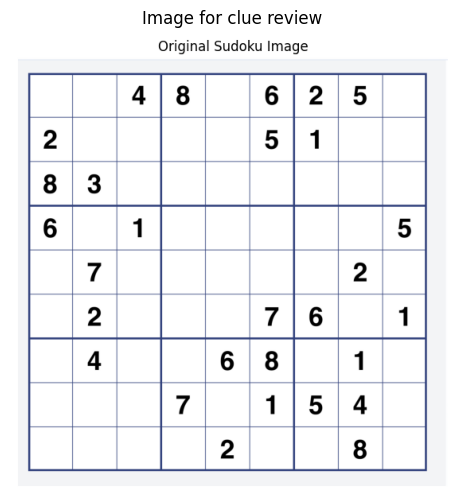

Image dimensions: (581, 559, 3)


In [13]:
# @title
# TW - 02/11/2026 - Load the image before preprocessing and grid extraction; cell order is required on a fresh runtime.
# TW - 02/11/2026 - UPDATED image input: retain an embedded reproducible demo and allow a fresh upload; reset prior review.
import base64
USE_DEMO_IMAGE = True
review_state = {'approved': False}
# TW - 02/11/2026 - A new image or OCR run clears every previous solution.
input_board = solution_board = solve_result = None
if USE_DEMO_IMAGE:
    demo_bytes = base64.b64decode('...')
    image = cv2.imdecode(np.frombuffer(demo_bytes,np.uint8),cv2.IMREAD_COLOR)
    print('Demo source: the original notebook saved image output, reprocessed locally.')
else:
    from google.colab import files
    uploaded=files.upload()
    if not uploaded:
        raise ValueError('No image uploaded')
    filename=next(iter(uploaded))
    image=cv2.imdecode(np.frombuffer(uploaded[filename],np.uint8),cv2.IMREAD_COLOR)
if image is None:
    raise ValueError('Unable to read image')
image_rgb=cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
plt.figure(figsize=(6,6));plt.imshow(image_rgb);plt.title('Image for clue review');plt.axis('off');plt.show()
print('Image dimensions:',image.shape)


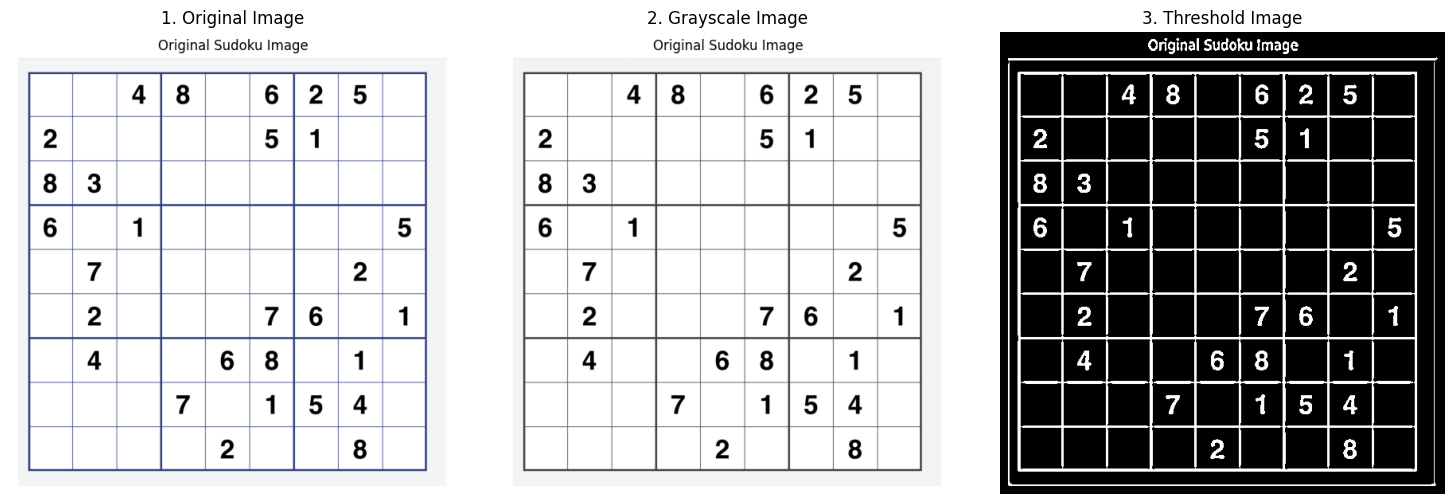

Image preprocessing completed successfully!
Grayscale dimensions: (581, 559)
Threshold dimensions: (581, 559)


In [14]:
# ==================================================
# STEP 3.2 - IMAGE PREPROCESSING
# ==================================================

# Step 1: Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Step 2: Apply Gaussian Blur
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Step 3: Apply Adaptive Thresholding
threshold = cv2.adaptiveThreshold(
    blurred,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    11,
    2
)

# Step 4: Display the preprocessing results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("1. Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("2. Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(threshold, cmap="gray")
plt.title("3. Threshold Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Image preprocessing completed successfully!")
print("Grayscale dimensions:", gray.shape)
print("Threshold dimensions:", threshold.shape)

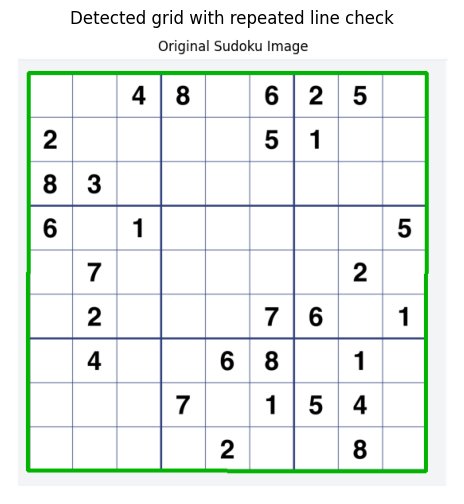

Grid boundary: [[ 23  51]
 [ 22 551]
 [522 552]
 [523  51]]


In [15]:
# TW - 02/11/2026 - UPDATED grid detection and OCR: distinct corners, repeated grid lines and explicit uncertain-cell evidence.
"""Grid extraction and OCR with explicit uncertain-cell results."""
from collections import Counter
import cv2
import numpy as np
import pytesseract


def preprocess_image(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    threshold = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv2.THRESH_BINARY_INV, 11, 2)
    return gray, threshold


# TW - 02/11/2026 - Order four distinct corners cyclically so coordinate ties cannot duplicate a corner.
def order_points(points):
    points = np.asarray(points, dtype=np.float32).reshape(4, 2)
    if len(np.unique(points, axis=0)) != 4:
        raise ValueError('Four distinct grid corners are required')
    centre = points.mean(axis=0)
    order = np.argsort(np.arctan2(points[:, 1]-centre[1], points[:, 0]-centre[0]))
    rect = points[order]
    first = min(range(4), key=lambda i: (sum(rect[i]), rect[i, 1], rect[i, 0]))
    rect = np.roll(rect, -first, axis=0)
    if abs(cv2.contourArea(rect)) < 1 or not cv2.isContourConvex(rect):
        raise ValueError('Grid corners must form a non-degenerate convex quadrilateral')
    return rect


def warp_grid(image, points, size=450):
    rect = order_points(points)
    destination = np.array([[0,0], [size-1,0], [size-1,size-1], [0,size-1]], np.float32)
    matrix = cv2.getPerspectiveTransform(rect, destination)
    return cv2.warpPerspective(image, matrix, (size, size))


# TW - 02/11/2026 - Check repeated grid boundaries; a four-sided page border alone is insufficient.
def has_sudoku_lines(warped):
    _, binary = preprocess_image(warped)
    size = binary.shape[0]
    # TW - 02/11/2026 - A plain rectangle is insufficient: require repeated horizontal and
    # TW - 02/11/2026 - vertical grid lines near the expected 10 boundaries of a 9 x 9 board.
    counts = []
    for axis in (0, 1):
        projection = (binary > 0).mean(axis=axis)
        count = 0
        for x in np.linspace(0, size-1, 10):
            lo, hi = max(0, int(x)-4), min(size, int(x)+5)
            count += bool(projection[lo:hi].max() >= 0.55)
        counts.append(count)
    return min(counts) >= 8


def detect_sudoku_grid(image, threshold=None):
    if threshold is None:
        _, threshold = preprocess_image(image)
    contours, _ = cv2.findContours(threshold, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    for contour in sorted(contours, key=cv2.contourArea, reverse=True):
        if cv2.contourArea(contour) < image.shape[0]*image.shape[1]*0.10:
            continue
        approx = cv2.approxPolyDP(contour, 0.02*cv2.arcLength(contour, True), True)
        if len(approx) != 4 or not cv2.isContourConvex(approx):
            continue
        try:
            warped = warp_grid(image, approx.reshape(4, 2))
        except ValueError:
            continue
        if has_sudoku_lines(warped):
            return approx, warped
    raise ValueError('No supported 9 x 9 Sudoku grid detected')


def extract_cells(warped):
    gray = cv2.cvtColor(warped, cv2.COLOR_BGR2GRAY)
    size = warped.shape[0] // 9
    return [[cv2.resize(gray[r*size+6:(r+1)*size-6, c*size+6:(c+1)*size-6], (50,50),
                        interpolation=cv2.INTER_AREA) for c in range(9)] for r in range(9)]


# TW - 02/11/2026 - Keep blank, digit and uncertain outcomes separate; failed OCR returns None rather than 0.
def recognize_digit_final(cell):
    """Return value/status/votes. Agreement is a heuristic, not a probability."""
    _, binary = cv2.threshold(cell, 0, 255, cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
    count, _, stats, _ = cv2.connectedComponentsWithStats(binary, 8)
    components = [tuple(int(x) for x in stats[i]) for i in range(1, count)]
    meaningful = [component for component in components if component[4] > 8]
    if not meaningful:
        return dict(value=0, status='blank', votes={}, agreement=0.0, ink_area=0)
    x, y, w, h, area = max(meaningful, key=lambda component: component[4])
    if area <= 30:
        return dict(value=None, status='uncertain', votes={}, agreement=0.0, ink_area=area)
    digit = binary[y:y+h, x:x+w]
    predictions = []
    for size in (80, 100, 120):
        scale = min(size/w, size/h)
        new_w, new_h = max(1, int(w*scale)), max(1, int(h*scale))
        resized = cv2.resize(digit, (new_w,new_h), interpolation=cv2.INTER_LINEAR)
        canvas = np.full((160,160), 255, np.uint8)
        sx, sy = (160-new_w)//2, (160-new_h)//2
        canvas[sy:sy+new_h, sx:sx+new_w] = 255-resized
        for psm in (6, 10, 13):
            config = f'--oem 3 --psm {psm} -c tessedit_char_whitelist=123456789'
            try:
                text = pytesseract.image_to_string(canvas, config=config, timeout=3).strip()
            except RuntimeError:
                text = ''  # TW - 02/11/2026 - An OCR timeout is uncertain, never a blank cell.
            if len(text) == 1 and text in '123456789':
                predictions.append(int(text))
    votes = Counter(predictions)
    winner, support = votes.most_common(1)[0] if votes else (None, 0)
    agreement = support / 9
    accepted = support >= 5 and (not votes or support > len(predictions)/2)
    return dict(value=winner if accepted else None,
                status='digit' if accepted else 'uncertain', votes=dict(votes),
                agreement=agreement, ink_area=area)


# TW - 02/11/2026 - Retain per-cell votes and uncertainty so the review step can expose OCR problems.
def recognize_cells(cells):
    results = [[recognize_digit_final(cell) for cell in row] for row in cells]
    board = [[result['value'] for result in row] for row in results]
    return board, results

sudoku_contour, detected_warp = detect_sudoku_grid(image,threshold)
detected_image=image.copy()
cv2.drawContours(detected_image,[sudoku_contour],-1,(0,180,0),3)
plt.figure(figsize=(6,6));plt.imshow(cv2.cvtColor(detected_image,cv2.COLOR_BGR2RGB))
plt.title('Detected grid with repeated line check');plt.axis('off');plt.show()
print('Grid boundary:',sudoku_contour.reshape(4,2))


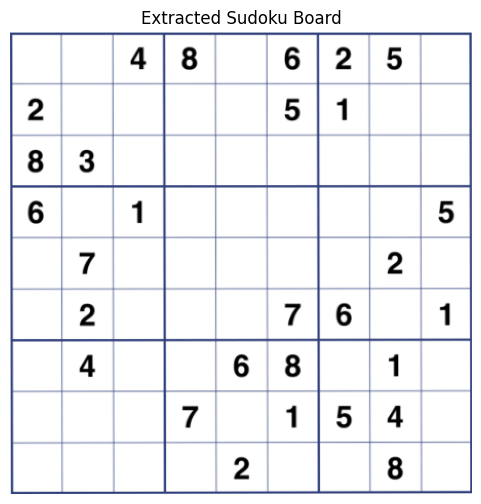

Perspective transformation completed!
Extracted board dimensions: (450, 450, 3)


In [16]:
# TW - 02/11/2026 - UPDATED perspective step: reuse the corrected corner ordering instead of redefining the faulty heuristic.
# Step 1: Get detected corner points
points = sudoku_contour.reshape(4, 2)

# Step 2: Order corner points
rect = order_points(points)

# Step 3: Set standard board size
board_size = 450

destination = np.array([
    [0, 0],
    [board_size - 1, 0],
    [board_size - 1, board_size - 1],
    [0, board_size - 1]
], dtype="float32")

# Step 4: Calculate perspective transformation
matrix = cv2.getPerspectiveTransform(rect, destination)

# Step 5: Apply transformation
warped_board = cv2.warpPerspective(
    image,
    matrix,
    (board_size, board_size)
)

# Step 6: Display extracted board
plt.figure(figsize=(6, 6))

plt.imshow(
    cv2.cvtColor(warped_board, cv2.COLOR_BGR2RGB)
)

plt.title("Extracted Sudoku Board")
plt.axis("off")
plt.show()

print("Perspective transformation completed!")
print("Extracted board dimensions:", warped_board.shape)


In [18]:
# ==================================================
# STEP 3.4B - EXTRACT 81 SUDOKU CELLS
# ==================================================

# Convert extracted board to grayscale
warped_gray = cv2.cvtColor(
    warped_board,
    cv2.COLOR_BGR2GRAY
)

# Calculate cell dimensions
cell_size = board_size // 9

# Store extracted cells
sudoku_cells = []

for row in range(9):

    row_cells = []

    for col in range(9):

        # Calculate cell coordinates
        x1 = col * cell_size
        y1 = row * cell_size

        x2 = x1 + cell_size
        y2 = y1 + cell_size

        # Extract individual cell
        cell = warped_gray[y1:y2, x1:x2]

        row_cells.append(cell)

    sudoku_cells.append(row_cells)

print("Sudoku cells extracted successfully!")
print("Total cells:", sum(len(row) for row in sudoku_cells))
print("Individual cell dimensions:", sudoku_cells[0][0].shape)

Sudoku cells extracted successfully!
Total cells: 81
Individual cell dimensions: (50, 50)


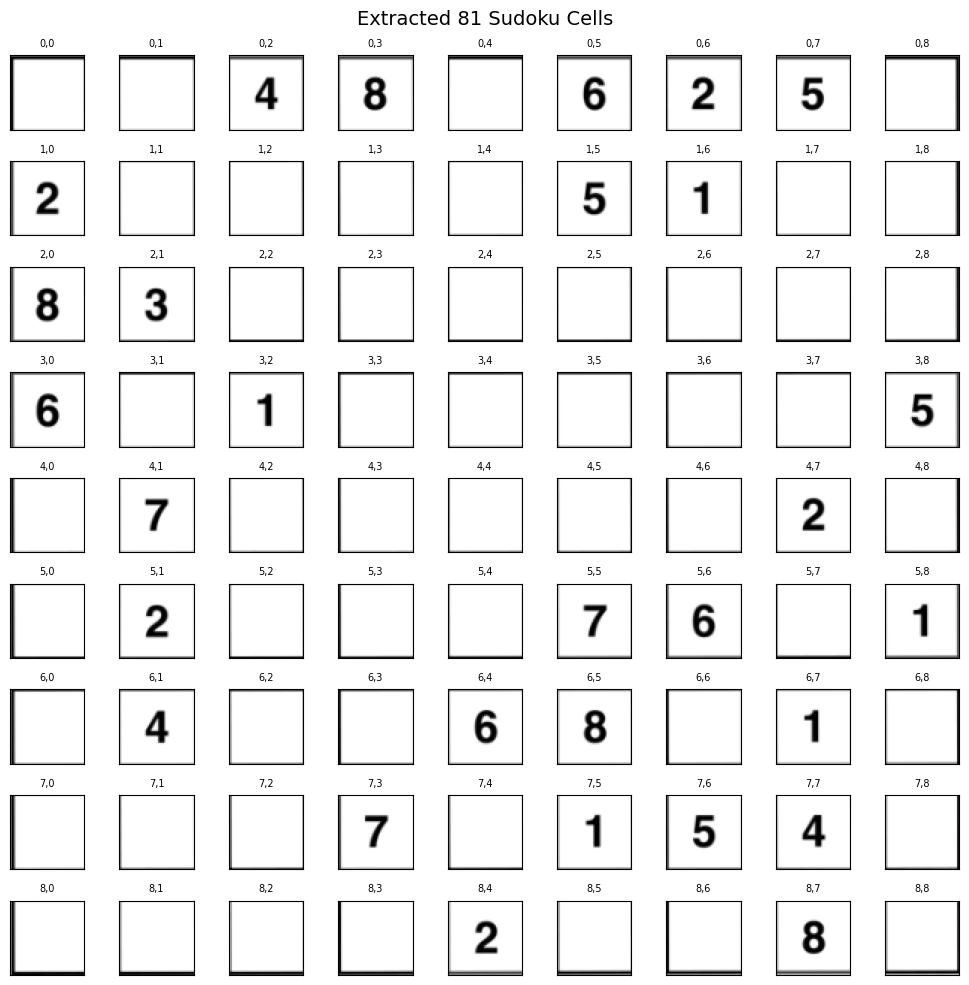

In [19]:
# ==================================================
# STEP 3.4C - DISPLAY ALL 81 SUDOKU CELLS
# ==================================================

fig, axes = plt.subplots(9, 9, figsize=(10, 10))

for row in range(9):
    for col in range(9):

        axes[row, col].imshow(
            sudoku_cells[row][col],
            cmap="gray"
        )

        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])

        axes[row, col].set_title(
            f"{row},{col}",
            fontsize=7
        )

plt.suptitle("Extracted 81 Sudoku Cells", fontsize=14)

plt.tight_layout()
plt.show()

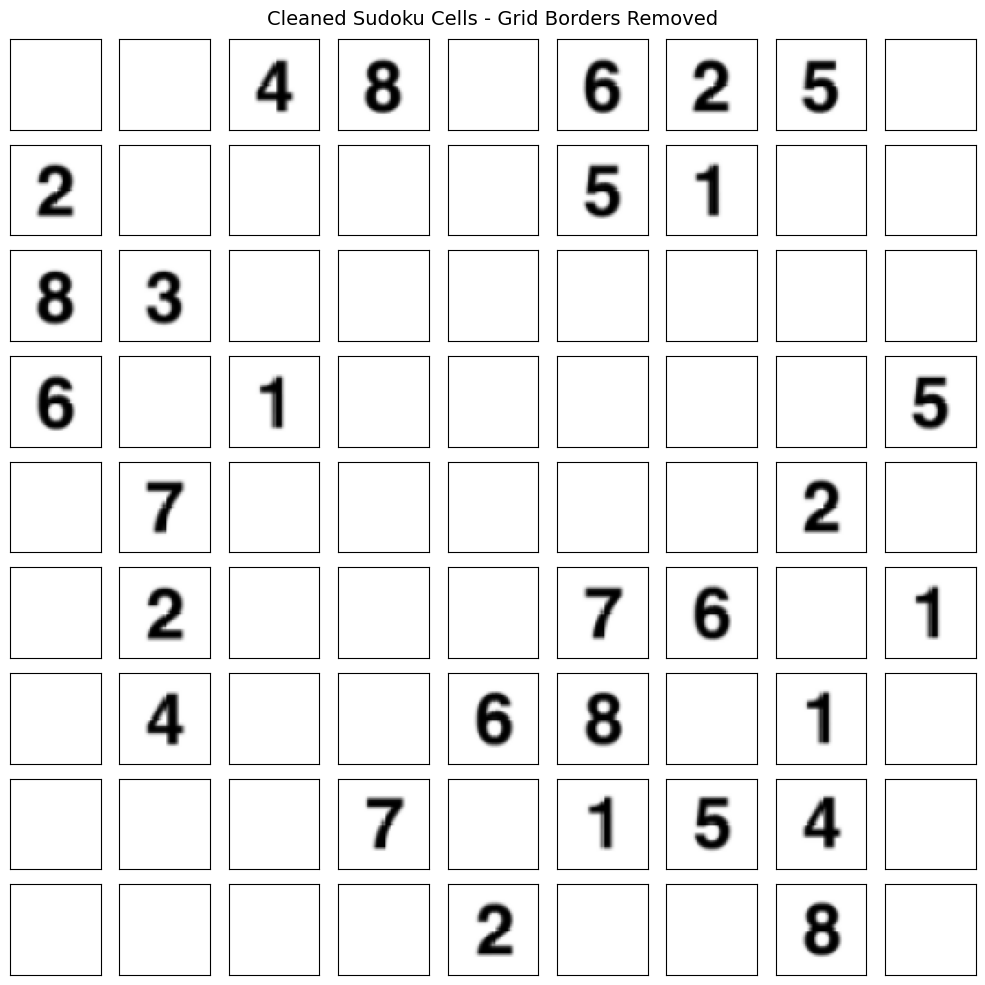

Cell cleaning completed!
Total cleaned cells: 81
Cell dimensions: (50, 50)


In [20]:
# ==================================================
# STEP 3.4D - CLEAN EXTRACTED SUDOKU CELLS
# ==================================================

# Store cleaned cells
cleaned_cells = []

# Remove 6 pixels from each side
margin = 6

for row in range(9):

    cleaned_row = []

    for col in range(9):

        # Get original extracted cell
        cell = sudoku_cells[row][col]

        # Remove grid lines around the edges
        cleaned_cell = cell[
            margin:-margin,
            margin:-margin
        ]

        # Resize back to 50x50 pixels
        cleaned_cell = cv2.resize(
            cleaned_cell,
            (50, 50),
            interpolation=cv2.INTER_AREA
        )

        cleaned_row.append(cleaned_cell)

    cleaned_cells.append(cleaned_row)

# Display cleaned cells
fig, axes = plt.subplots(9, 9, figsize=(10, 10))

for row in range(9):
    for col in range(9):

        axes[row, col].imshow(
            cleaned_cells[row][col],
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])

plt.suptitle(
    "Cleaned Sudoku Cells - Grid Borders Removed",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("Cell cleaning completed!")
print("Total cleaned cells:", sum(len(row) for row in cleaned_cells))
print("Cell dimensions:", cleaned_cells[0][0].shape)

In [21]:
# TW - 02/11/2026 - UPDATED OCR setup: report the engine already checked in the environment cell.
print('Tesseract ready:',pytesseract.get_tesseract_version())


Tesseract ready: 5.3.4


## 3. OCR with explicit uncertainty
Each cell is classified as blank, digit, or uncertain. Digit regions with failed or
insufficiently agreeing OCR attempts return `None`, displayed as `?`, instead of zero.
Five agreeing predictions out of nine attempts are required for a provisional digit.
Even agreeing predictions can be wrong: the next step requires checking all cells.


**TW - 02/11/2026 - UPDATED recognition explanation: uncertain cells remain unresolved until reviewed.**


In [22]:
# TW - 02/11/2026 - UPDATED OCR location: reuse the evidence-producing recognition function defined earlier.
# TW - 02/11/2026 - recognize_digit_final and recognize_cells are defined in Step 3.3A.
# TW - 02/11/2026 - Their per-cell evidence records votes, agreement, ink area and status.


In [23]:
# TW - 02/11/2026 - UPDATED OCR output: show unresolved cells as ? and retain recognition evidence.
final_recognized_board, ocr_results = recognize_cells(cleaned_cells)
review_state={'approved':False}
# TW - 02/11/2026 - A new image or OCR run clears every previous solution.
input_board = solution_board = solve_result = None
print('OCR matrix (? = unresolved, 0 = blank):')
for row in final_recognized_board:
    print(['?' if n is None else n for n in row])
uncertain=[(r+1,c+1) for r in range(9) for c in range(9) if ocr_results[r][c]['status']=='uncertain']
print('Cells requiring correction:',uncertain)
print('Automatic status:',solve_recognized_board(final_recognized_board)['status'])


OCR matrix (? = unresolved, 0 = blank):
[0, 0, 4, 8, 0, 6, 2, 5, 0]
[2, 0, 0, 0, 0, 5, 1, 0, 0]
[8, 3, 0, 0, 0, 0, 0, 0, 0]
[6, 0, 1, 0, 0, 0, 0, 0, 5]
[0, 7, 0, 0, 0, 0, 0, 2, 0]
[0, 2, 0, 0, 0, '?', 6, 0, 1]
[0, 4, 0, 0, 6, 8, 0, 1, 0]
[0, 0, 0, '?', 0, 1, 5, 4, 0]
[0, 0, 0, 0, 2, 0, 0, 8, 0]
Cells requiring correction: [(6, 6), (8, 4)]
Automatic status: uncertain_ocr


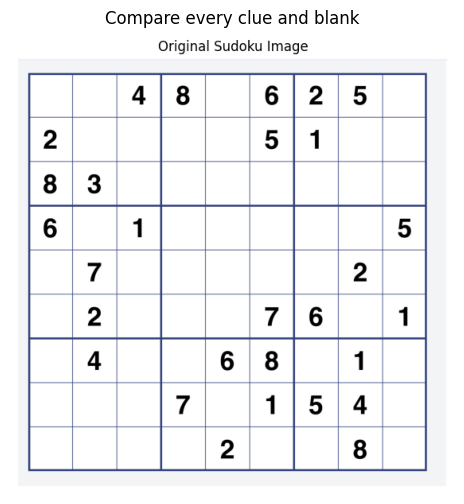

Review grid: rows 1-9 top to bottom, columns 1-9 left to right.
Replace ? cells; use 0 only for a confirmed blank. Run all can finish while review is pending.


GridBox(children=(Text(value='0', layout=Layout(width='44px')), Text(value='0', layout=Layout(width='44px')), …

Checkbox(value=False, description='I checked all 81 cells against the image', indent=False)

Button(description='Approve clues and solve', layout=Layout(width='220px'), style=ButtonStyle())

Output()

In [24]:
# TW - 02/11/2026 - Review is a normal waiting state; the button validates, solves and displays the reviewed puzzle.
import hashlib
import ipywidgets as widgets
from IPython.display import display

review_state = {'approved': False}
input_board = solution_board = solve_result = None
review_fields = []
review_confirmation = widgets.Checkbox(
    value=False, description='I checked all 81 cells against the image', indent=False)
approve_button = widgets.Button(description='Approve clues and solve',
                                layout=widgets.Layout(width='220px'))
review_output = widgets.Output()


# TW - 02/11/2026 - Clear old solutions whenever approval changes, so stale results cannot pass later checks.
def invalidate_image_solution():
    global input_board, solution_board, solve_result
    input_board = solution_board = solve_result = None


def reset_approval(change):
    review_state.clear()
    review_state['approved'] = False
    invalidate_image_solution()
    review_confirmation.value = False
    with review_output:
        review_output.clear_output(wait=True)
        print('Clue changed. Check the grid, tick the confirmation box, then approve and solve.')


def reset_confirmation(change):
    if not change['new']:
        review_state.clear()
        review_state['approved'] = False
        invalidate_image_solution()
        with review_output:
            review_output.clear_output(wait=True)
            print('Waiting for clue review and confirmation. No image solution is being claimed.')


review_confirmation.observe(reset_confirmation, names='value')
for r in range(9):
    row = []
    for c in range(9):
        value = final_recognized_board[r][c]
        field = widgets.Text(value='?' if value is None else str(value),
                             layout=widgets.Layout(width='44px'), description='')
        field.observe(reset_approval, names='value')
        row.append(field)
    review_fields.append(row)


# TW - 02/11/2026 - Missing review returns review_required instead of raising a traceback during Run all.
# TW - 02/11/2026 - Use MRV + forward checking and the increased budget for image solving; preserve the review gate.
def run_image_solver(time_limit=5.0, node_limit=2_500_000, check_unique=False, method='mrv_fc'):
    global input_board, solution_board, solve_result
    invalidate_image_solution()
    if not review_state.get('approved') or not review_confirmation.value:
        solve_result = {'status': 'review_required', 'solution': None}
        print('WAITING: correct any ? cells in Step 3.6, confirm all clues, and click Approve clues and solve.')
        return solve_result
    if review_state.get('image_digest') != hashlib.sha256(image.tobytes()).hexdigest():
        review_state.clear()
        review_state['approved'] = False
        review_confirmation.value = False
        solve_result = {'status': 'review_required', 'solution': None}
        print('The image changed. Repeat OCR and clue review before solving.')
        return solve_result
    input_board = [row.copy() for row in review_state['board']]
    solve_result = solve_recognized_board(input_board, reviewed=True, time_limit=time_limit,
                                         node_limit=node_limit, check_unique=check_unique, method=method)
    print('Search method:', method, '| budget:', time_limit, 'seconds /', node_limit, 'candidate attempts')
    print('Solver status:', solve_result['status'])
    if solve_result['status'] not in ('solved', 'multiple'):
        print('Search stopped without a verified image solution:', solve_result['status'])
        return solve_result
    candidate = solve_result['solution']
    if not verify_solution(input_board, candidate):
        solve_result = {'status': 'verification_failed', 'solution': None}
        print('Solution verification failed. No image solution is being claimed.')
        return solve_result
    solution_board = candidate
    print('Valid completion for the reviewed clues. Seconds:', round(solve_result['seconds'], 4))
    print('Counters:', solve_result['stats'])
    print('Uniqueness:', solve_result['unique'], '(None means not checked)')
    return solve_result


# TW - 02/11/2026 - The same callback works before or after the remaining notebook cells have run.
def approve_review(button):
    review_state.clear()
    review_state['approved'] = False
    invalidate_image_solution()
    with review_output:
        review_output.clear_output(wait=True)
        if not review_confirmation.value:
            print('Check every cell against the image and tick the confirmation box.')
            return
        try:
            reviewed = [[int(field.value.strip()) for field in row] for row in review_fields]
        except ValueError:
            print('Replace every ? with a digit 1-9 or 0 for a confirmed blank.')
            return
        if not validate_board(reviewed):
            print('Reviewed clues contain invalid values or Sudoku conflicts.')
            return
        if not any(n for row in reviewed for n in row):
            print('No clues recognised. Upload or review an image containing puzzle clues.')
            return
        review_state.update(approved=True, board=reviewed,
                            image_digest=hashlib.sha256(image.tobytes()).hexdigest())
        result = run_image_solver()
        if result['status'] in ('solved', 'multiple'):
            if callable(globals().get('show_image_solution')):
                show_image_solution()
            else:
                for row in solution_board:
                    print(row)
                print('Solved. Run Step 4.2 to initialise the visual display.')


approve_button.on_click(approve_review)
plt.figure(figsize=(6, 6))
plt.imshow(image_rgb)
plt.title('Compare every clue and blank')
plt.axis('off')
plt.show()
print('Review grid: rows 1-9 top to bottom, columns 1-9 left to right.')
print('Replace ? cells; use 0 only for a confirmed blank. Run all can finish while review is pending.')
display(widgets.GridBox([f for row in review_fields for f in row],
                        layout=widgets.Layout(grid_template_columns='repeat(9,44px)', grid_gap='2px')))
display(review_confirmation, approve_button, review_output)


## 4. Solve the reviewed puzzle
Run all may continue while the review is pending; this is a waiting state, not an error.
In Step 3.6, compare every cell with the image, replace each ?, tick the confirmation
box and click **Approve clues and solve**. The button solves and updates the review
output automatically. Step 4.1 can also rerun an approved puzzle with the stated limits.

**TW - 02/11/2026 - Removed the traceback for pending review and connected approval directly to solving.**

**TW - 02/11/2026 - Output visibility fix:** clicking the approval button prints the solver status, timing, counters and solution directly below that button in Step 3.6. Running Step 4.1 prints the results below Step 4.1; running Step 4.2 prints the visual result below Step 4.2. After reviewing the grid, do not use Run all again: it recreates the review controls and resets your corrections. Use the approval button or run only the solve/display/check cells.

**TW - 02/11/2026 - Improved image search:** the approval button uses `mrv_fc`, 5 seconds and 2,500,000 candidate attempts. The numeric baseline remains available through `solve_board`. To rerun an already reviewed image with another method, use `run_image_solver(method="backtracking", time_limit=1.0, node_limit=500_000)` in the solve cell. Changing search settings does not bypass clue review.


Search method: mrv_fc | budget: 5.0 seconds / 2500000 candidate attempts
Solver status: solved
Valid completion for the reviewed clues. Seconds: 0.0072
Counters: {'candidates': 133, 'assignments': 133, 'checks': 7859, 'backtracks': 77, 'forward_checks': 995, 'pruned_values': 460, 'domain_wipeouts': 4}
Uniqueness: None (None means not checked)


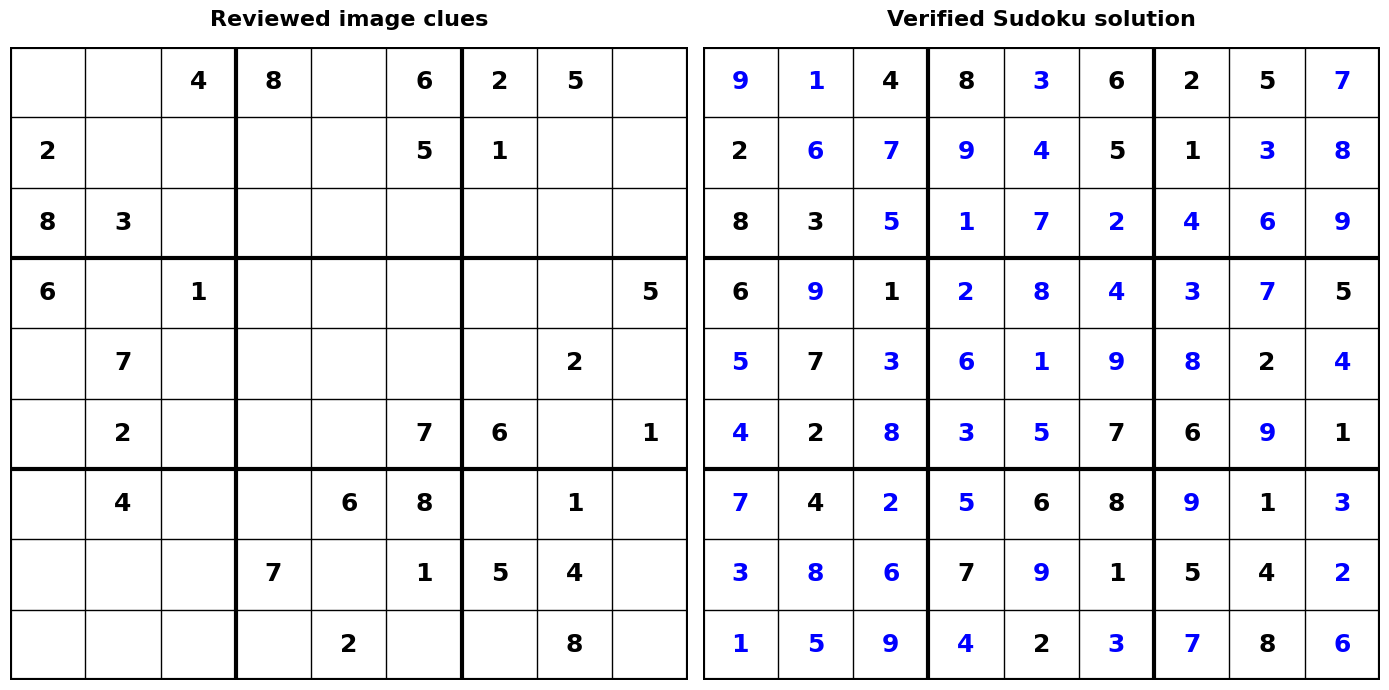

SUCCESS: Sudoku rules and preservation of the reviewed clues verified.
OCR image correspondence depends on the clue review.


In [32]:
# TW - 02/11/2026 - A pending review is normal: show guidance without crashing Run all or claiming a solution.
if not callable(globals().get('run_image_solver')):
    input_board = solution_board = solve_result = None
    print('Run Step 3.6 to initialise the review controls, then approve the clues.')
else:
    run_image_solver()
    if solution_board is not None and callable(globals().get('show_image_solution')):
        show_image_solution()


## 5. Verify and visualise
The verifier checks completeness, all Sudoku constraints, and preservation of the
reviewed clues. Blue digits were added by the solver. Image correspondence depends
on accurate clue review; this is not an independent proof of OCR accuracy.


**TW - 02/11/2026 - UPDATED verification scope: Sudoku validity is checked against reviewed clues, not assumed OCR accuracy.**


In [33]:
# ==================================================
# STEP 4.2A - VISUAL SUDOKU SOLUTION DISPLAY
# ==================================================

import matplotlib.pyplot as plt
import numpy as np

def display_sudoku(ax, board, original=None, title="Sudoku"):

    # Set board limits
    ax.set_xlim(0, 9)
    ax.set_ylim(9, 0)

    # Draw Sudoku grid
    for i in range(10):

        # Thicker lines for 3x3 boxes
        linewidth = 3 if i % 3 == 0 else 1

        ax.plot(
            [i, i],
            [0, 9],
            color="black",
            linewidth=linewidth
        )

        ax.plot(
            [0, 9],
            [i, i],
            color="black",
            linewidth=linewidth
        )

    # Display numbers
    for row in range(9):
        for col in range(9):

            number = board[row][col]

            if number != 0:

                # Default number colour
                color = "black"

                # Highlight automatically solved numbers
                if original is not None:
                    if original[row][col] == 0:
                        color = "blue"

                ax.text(
                    col + 0.5,
                    row + 0.5,
                    str(number),
                    ha="center",
                    va="center",
                    fontsize=18,
                    fontweight="bold",
                    color=color
                )

    ax.set_title(
        title,
        fontsize=16,
        fontweight="bold",
        pad=15
    )

    ax.axis("off")


print("Sudoku display function created successfully!")

Sudoku display function created successfully!


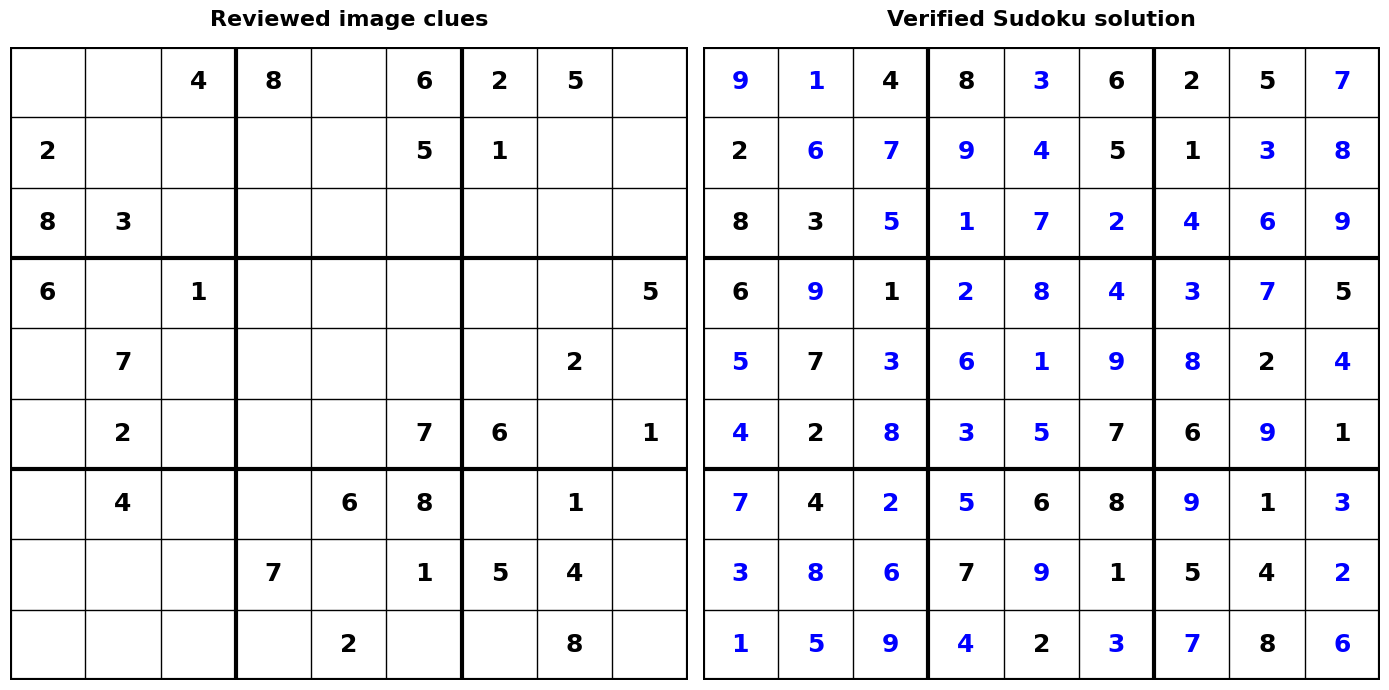

SUCCESS: Sudoku rules and preservation of the reviewed clues verified.
OCR image correspondence depends on the clue review.


In [34]:
# TW - 02/11/2026 - Print in the calling cell; the approval callback already captures its own output.
# TW - 02/11/2026 - Do not clear here: that erased the solver status, timing and counters.
def show_image_solution():
    if not review_state.get('approved') or not review_confirmation.value:
        print('WAITING: review Step 3.6 and click Approve clues and solve. No image solution is being claimed.')
        return False
    if input_board is None or solution_board is None:
        print('No solution displayed. Solver status:', (solve_result or {}).get('status', 'not_run'))
        return False
    if review_state.get('image_digest') != hashlib.sha256(image.tobytes()).hexdigest():
        invalidate_image_solution()
        review_state.clear()
        review_state['approved'] = False
        review_confirmation.value = False
        print('The image changed. Repeat OCR and clue review.')
        return False
    if not verify_solution(input_board, solution_board):
        invalidate_image_solution()
        print('Verification failed. No image solution is being claimed.')
        return False
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    display_sudoku(axes[0], input_board, title='Reviewed image clues')
    display_sudoku(axes[1], solution_board, original=input_board, title='Verified Sudoku solution')
    plt.tight_layout()
    plt.show()
    print('SUCCESS: Sudoku rules and preservation of the reviewed clues verified.')
    print('OCR image correspondence depends on the clue review.')
    return True

if 'review_output' in globals():
    show_image_solution()
else:
    print('Run Step 3.6 first to initialise clue review.')


## 6. Final checks and reproducible numeric benchmark
These checks distinguish solver correctness from image recognition. The source
archive contains 31 regression tests and OCR measurements against ground truth.
The following optional benchmark uses documented public puzzles rather than
assigning difficulty labels from the number of blanks.


**TW - 02/11/2026 - UPDATED evaluation scope: separate solution validity from recognition accuracy and public puzzle performance.**


In [35]:
# TW - 02/11/2026 - Safeguards can pass while review is pending; pending review is never reported as a solved image.
assert solve_recognized_board([[0]*9 for _ in range(9)], reviewed=True)['status'] == 'empty_recognition'
print('PASS: empty-recognition protection.')
if (globals().get('review_state', {}).get('approved')
        and globals().get('solution_board') is not None):
    assert verify_solution(input_board, solution_board)
    assert solve_recognized_board(input_board, reviewed=False)['status'] == 'review_required'
    print('PASS: solution validity, reviewed-clue preservation and review-required protection.')
elif globals().get('review_state', {}).get('approved'):
    print('No verified image solution. Solver status:', (globals().get('solve_result') or {}).get('status', 'not_run'))
else:
    print('WAITING FOR REVIEW: no image solution has been verified yet. Use Approve clues and solve in Step 3.6.')
print('OCR accuracy must be measured separately against known image ground truth.')


PASS: empty-recognition protection.
PASS: solution validity, reviewed-clue preservation and review-required protection.
OCR accuracy must be measured separately against known image ground truth.


## 7. Public puzzle benchmark
Source: Peter Norvig, [Solving Every Sudoku Puzzle](https://norvig.com/sudoku.html),
[easy50](https://norvig.com/easy50.txt) and [top95](https://norvig.com/top95.txt).
The first ten puzzles from each file are embedded below in original file order.
Run three repeats, capped at one second or 500,000 candidate attempts per run.
Both wall-clock timeouts and candidate-limit outcomes are retained. The median
including stopped attempts is not a solved-puzzle time. Timings vary by device.

**TW - 02/11/2026 - ADDED benchmark sources and methodology: retain stopped attempts and report both search budgets.**


In [37]:
# TW - 02/11/2026 - Enabled for this measured benchmark run; set False below to skip it during Run all.
RUN_PUBLIC_BENCHMARK = False
if RUN_PUBLIC_BENCHMARK:
    # TW - 02/11/2026 - ADDED reproducible public benchmark: first ten puzzles per source, three repeats, CSV results.
    import csv, statistics
    benchmark_cases = [{'id': 'easy50_01', 'group': 'easy50', 'source_index': 1, 'board': [[0, 0, 3, 0, 2, 0, 6, 0, 0], [9, 0, 0, 3, 0, 5, 0, 0, 1], [0, 0, 1, 8, 0, 6, 4, 0, 0], [0, 0, 8, 1, 0, 2, 9, 0, 0], [7, 0, 0, 0, 0, 0, 0, 0, 8], [0, 0, 6, 7, 0, 8, 2, 0, 0], [0, 0, 2, 6, 0, 9, 5, 0, 0], [8, 0, 0, 2, 0, 3, 0, 0, 9], [0, 0, 5, 0, 1, 0, 3, 0, 0]]}, {'id': 'easy50_02', 'group': 'easy50', 'source_index': 2, 'board': [[2, 0, 0, 0, 8, 0, 3, 0, 0], [0, 6, 0, 0, 7, 0, 0, 8, 4], [0, 3, 0, 5, 0, 0, 2, 0, 9], [0, 0, 0, 1, 0, 5, 4, 0, 8], [0, 0, 0, 0, 0, 0, 0, 0, 0], [4, 0, 2, 7, 0, 6, 0, 0, 0], [3, 0, 1, 0, 0, 7, 0, 4, 0], [7, 2, 0, 0, 4, 0, 0, 6, 0], [0, 0, 4, 0, 1, 0, 0, 0, 3]]}, {'id': 'easy50_03', 'group': 'easy50', 'source_index': 3, 'board': [[0, 0, 0, 0, 0, 0, 9, 0, 7], [0, 0, 0, 4, 2, 0, 1, 8, 0], [0, 0, 0, 7, 0, 5, 0, 2, 6], [1, 0, 0, 9, 0, 4, 0, 0, 0], [0, 5, 0, 0, 0, 0, 0, 4, 0], [0, 0, 0, 5, 0, 7, 0, 0, 9], [9, 2, 0, 1, 0, 8, 0, 0, 0], [0, 3, 4, 0, 5, 9, 0, 0, 0], [5, 0, 7, 0, 0, 0, 0, 0, 0]]}, {'id': 'easy50_04', 'group': 'easy50', 'source_index': 4, 'board': [[0, 3, 0, 0, 5, 0, 0, 4, 0], [0, 0, 8, 0, 1, 0, 5, 0, 0], [4, 6, 0, 0, 0, 0, 0, 1, 2], [0, 7, 0, 5, 0, 2, 0, 8, 0], [0, 0, 0, 6, 0, 3, 0, 0, 0], [0, 4, 0, 1, 0, 9, 0, 3, 0], [2, 5, 0, 0, 0, 0, 0, 9, 8], [0, 0, 1, 0, 2, 0, 6, 0, 0], [0, 8, 0, 0, 6, 0, 0, 2, 0]]}, {'id': 'easy50_05', 'group': 'easy50', 'source_index': 5, 'board': [[0, 2, 0, 8, 1, 0, 7, 4, 0], [7, 0, 0, 0, 0, 3, 1, 0, 0], [0, 9, 0, 0, 0, 2, 8, 0, 5], [0, 0, 9, 0, 4, 0, 0, 8, 7], [4, 0, 0, 2, 0, 8, 0, 0, 3], [1, 6, 0, 0, 3, 0, 2, 0, 0], [3, 0, 2, 7, 0, 0, 0, 6, 0], [0, 0, 5, 6, 0, 0, 0, 0, 8], [0, 7, 6, 0, 5, 1, 0, 9, 0]]}, {'id': 'easy50_06', 'group': 'easy50', 'source_index': 6, 'board': [[1, 0, 0, 9, 2, 0, 0, 0, 0], [5, 2, 4, 0, 1, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 7, 0], [0, 5, 0, 0, 0, 8, 1, 0, 2], [0, 0, 0, 0, 0, 0, 0, 0, 0], [4, 0, 2, 7, 0, 0, 0, 9, 0], [0, 6, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 3, 0, 9, 4, 5], [0, 0, 0, 0, 7, 1, 0, 0, 6]]}, {'id': 'easy50_07', 'group': 'easy50', 'source_index': 7, 'board': [[0, 4, 3, 0, 8, 0, 2, 5, 0], [6, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 1, 0, 9, 4], [9, 0, 0, 0, 0, 4, 0, 7, 0], [0, 0, 0, 6, 0, 8, 0, 0, 0], [0, 1, 0, 2, 0, 0, 0, 0, 3], [8, 2, 0, 5, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 5], [0, 3, 4, 0, 9, 0, 7, 1, 0]]}, {'id': 'easy50_08', 'group': 'easy50', 'source_index': 8, 'board': [[4, 8, 0, 0, 0, 6, 9, 0, 2], [0, 0, 2, 0, 0, 8, 0, 0, 1], [9, 0, 0, 3, 7, 0, 0, 6, 0], [8, 4, 0, 0, 1, 0, 2, 0, 0], [0, 0, 3, 7, 0, 4, 1, 0, 0], [0, 0, 1, 0, 6, 0, 0, 4, 9], [0, 2, 0, 0, 8, 5, 0, 0, 7], [7, 0, 0, 9, 0, 0, 6, 0, 0], [6, 0, 9, 2, 0, 0, 0, 1, 8]]}, {'id': 'easy50_09', 'group': 'easy50', 'source_index': 9, 'board': [[0, 0, 0, 9, 0, 0, 0, 0, 2], [0, 5, 0, 1, 2, 3, 4, 0, 0], [0, 3, 0, 0, 0, 0, 1, 6, 0], [9, 0, 8, 0, 0, 0, 0, 0, 0], [0, 7, 0, 0, 0, 0, 0, 9, 0], [0, 0, 0, 0, 0, 0, 2, 0, 5], [0, 9, 1, 0, 0, 0, 0, 5, 0], [0, 0, 7, 4, 3, 9, 0, 2, 0], [4, 0, 0, 0, 0, 7, 0, 0, 0]]}, {'id': 'easy50_10', 'group': 'easy50', 'source_index': 10, 'board': [[0, 0, 1, 9, 0, 0, 0, 0, 3], [9, 0, 0, 7, 0, 0, 1, 6, 0], [0, 3, 0, 0, 0, 5, 0, 0, 7], [0, 5, 0, 0, 0, 0, 0, 0, 9], [0, 0, 4, 3, 0, 2, 6, 0, 0], [2, 0, 0, 0, 0, 0, 0, 7, 0], [6, 0, 0, 1, 0, 0, 0, 3, 0], [0, 4, 2, 0, 0, 7, 0, 0, 6], [5, 0, 0, 0, 0, 6, 8, 0, 0]]}, {'id': 'top95_01', 'group': 'top95', 'source_index': 1, 'board': [[4, 0, 0, 0, 0, 0, 8, 0, 5], [0, 3, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 7, 0, 0, 0, 0, 0], [0, 2, 0, 0, 0, 0, 0, 6, 0], [0, 0, 0, 0, 8, 0, 4, 0, 0], [0, 0, 0, 0, 1, 0, 0, 0, 0], [0, 0, 0, 6, 0, 3, 0, 7, 0], [5, 0, 0, 2, 0, 0, 0, 0, 0], [1, 0, 4, 0, 0, 0, 0, 0, 0]]}, {'id': 'top95_02', 'group': 'top95', 'source_index': 2, 'board': [[5, 2, 0, 0, 0, 6, 0, 0, 0], [0, 0, 0, 0, 0, 0, 7, 0, 1], [3, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 4, 0, 0, 8, 0, 0], [6, 0, 0, 0, 0, 0, 0, 5, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 4, 1, 8, 0, 0, 0, 0, 0], [0, 0, 0, 0, 3, 0, 0, 2, 0], [0, 0, 8, 7, 0, 0, 0, 0, 0]]}, {'id': 'top95_03', 'group': 'top95', 'source_index': 3, 'board': [[6, 0, 0, 0, 0, 0, 8, 0, 3], [0, 4, 0, 7, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 5, 0, 4, 0, 7, 0], [3, 0, 0, 2, 0, 0, 0, 0, 0], [1, 0, 6, 0, 0, 0, 0, 0, 0], [0, 2, 0, 0, 0, 0, 0, 5, 0], [0, 0, 0, 0, 8, 0, 6, 0, 0], [0, 0, 0, 0, 1, 0, 0, 0, 0]]}, {'id': 'top95_04', 'group': 'top95', 'source_index': 4, 'board': [[4, 8, 0, 3, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 7, 1], [0, 2, 0, 0, 0, 0, 0, 0, 0], [7, 0, 5, 0, 0, 0, 0, 6, 0], [0, 0, 0, 2, 0, 0, 8, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 1, 0, 7, 6, 0, 0, 0], [3, 0, 0, 0, 0, 0, 4, 0, 0], [0, 0, 0, 0, 5, 0, 0, 0, 0]]}, {'id': 'top95_05', 'group': 'top95', 'source_index': 5, 'board': [[0, 0, 0, 0, 1, 4, 0, 0, 0], [0, 3, 0, 0, 0, 0, 2, 0, 0], [0, 7, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 9, 0, 0, 0, 3, 0], [6, 0, 1, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 8, 0], [2, 0, 0, 0, 0, 0, 1, 0, 4], [0, 0, 0, 0, 5, 0, 6, 0, 0], [0, 0, 0, 7, 0, 8, 0, 0, 0]]}, {'id': 'top95_06', 'group': 'top95', 'source_index': 6, 'board': [[0, 0, 0, 0, 0, 0, 5, 2, 0], [0, 8, 0, 4, 0, 0, 0, 0, 0], [0, 3, 0, 0, 0, 9, 0, 0, 0], [5, 0, 1, 0, 0, 0, 6, 0, 0], [2, 0, 0, 7, 0, 0, 0, 0, 0], [0, 0, 0, 3, 0, 0, 0, 0, 0], [6, 0, 0, 0, 1, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 7, 0, 4], [0, 0, 0, 0, 0, 0, 0, 3, 0]]}, {'id': 'top95_07', 'group': 'top95', 'source_index': 7, 'board': [[6, 0, 2, 0, 5, 0, 0, 0, 0], [0, 0, 0, 0, 0, 3, 0, 4, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [4, 3, 0, 0, 0, 8, 0, 0, 0], [0, 1, 0, 0, 0, 0, 2, 0, 0], [0, 0, 0, 0, 0, 0, 7, 0, 0], [5, 0, 0, 2, 7, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 8, 1], [0, 0, 0, 6, 0, 0, 0, 0, 0]]}, {'id': 'top95_08', 'group': 'top95', 'source_index': 8, 'board': [[0, 5, 2, 4, 0, 0, 0, 0, 0], [0, 0, 0, 0, 7, 0, 1, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 8, 0, 2, 0, 0, 0], [3, 0, 0, 0, 0, 0, 6, 0, 0], [0, 9, 0, 5, 0, 0, 0, 0, 0], [1, 0, 6, 0, 3, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 8, 9], [7, 0, 0, 0, 0, 0, 0, 0, 0]]}, {'id': 'top95_09', 'group': 'top95', 'source_index': 9, 'board': [[6, 0, 2, 0, 5, 0, 0, 0, 0], [0, 0, 0, 0, 0, 4, 0, 3, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [4, 3, 0, 0, 0, 8, 0, 0, 0], [0, 1, 0, 0, 0, 0, 2, 0, 0], [0, 0, 0, 0, 0, 0, 7, 0, 0], [5, 0, 0, 2, 7, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 8, 1], [0, 0, 0, 6, 0, 0, 0, 0, 0]]}, {'id': 'top95_10', 'group': 'top95', 'source_index': 10, 'board': [[0, 9, 2, 3, 0, 0, 0, 0, 0], [0, 0, 0, 0, 8, 0, 1, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [1, 0, 7, 0, 4, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 6, 5], [8, 0, 0, 0, 0, 0, 0, 0, 0], [0, 6, 0, 5, 0, 2, 0, 0, 0], [4, 0, 0, 0, 0, 0, 7, 0, 0], [0, 0, 0, 9, 0, 0, 0, 0, 0]]}]
    benchmark_rows=[]
    for case in benchmark_cases:
        trials=[solve_board(case['board'],time_limit=1.0,node_limit=500_000) for _ in range(3)]
        for repeat,trial in enumerate(trials,start=1):
            assert trial['solution'] is None or verify_solution(case['board'],trial['solution'])
            benchmark_rows.append(dict(id=case['id'],group=case['group'],repeat=repeat,
                                       status=trial['status'],seconds=trial['seconds'],**trial['stats']))
        print(case['id'],[t['status'] for t in trials],
              'median seconds:',round(statistics.median(t['seconds'] for t in trials),4))
    with open('sudoku_benchmark_results.csv','w',newline='') as stream:
        writer=csv.DictWriter(stream,fieldnames=list(benchmark_rows[0]));writer.writeheader();writer.writerows(benchmark_rows)
    print('Saved sudoku_benchmark_results.csv')

else:
    print('Public benchmark skipped. Set RUN_PUBLIC_BENCHMARK = True and rerun this cell when needed.')


easy50_01 ['solved', 'solved', 'solved'] median seconds: 0.0046
easy50_02 ['solved', 'solved', 'solved'] median seconds: 0.0058
easy50_03 ['solved', 'solved', 'solved'] median seconds: 0.3632
easy50_04 ['solved', 'solved', 'solved'] median seconds: 0.0304
easy50_05 ['solved', 'solved', 'solved'] median seconds: 0.0015
easy50_06 ['timeout', 'timeout', 'timeout'] median seconds: 1.0001
easy50_07 ['solved', 'solved', 'solved'] median seconds: 0.1311
easy50_08 ['solved', 'solved', 'solved'] median seconds: 0.0031
easy50_09 ['timeout', 'timeout', 'timeout'] median seconds: 1.0001
easy50_10 ['solved', 'solved', 'solved'] median seconds: 0.0999
top95_01 ['timeout', 'timeout', 'timeout'] median seconds: 1.0001
top95_02 ['timeout', 'timeout', 'timeout'] median seconds: 1.0001
top95_03 ['timeout', 'timeout', 'timeout'] median seconds: 1.0001
top95_04 ['timeout', 'timeout', 'timeout'] median seconds: 1.0001
top95_05 ['timeout', 'timeout', 'timeout'] median seconds: 1.0
top95_06 ['timeout', 'timeo

## 8. Compare search budgets and MRV with forward checking

**TW - 02/11/2026 - Added a controlled comparison of both requested improvements.**

| Method | Budget | Time limit | Candidate limit |
|---|---|---:|---:|
| Plain backtracking | Original | 1 second | 500,000 |
| Plain backtracking | Increased | 5 seconds | 2,500,000 |
| MRV + forward checking | Original | 1 second | 500,000 |
| MRV + forward checking | Increased | 5 seconds | 2,500,000 |

Use the same first ten easy50 and first ten top95 puzzles as Section 7, with three
independent repeats per puzzle and configuration: 240 attempts in total. Execution
order rotates by puzzle and repeat. All returned solutions are verified and all
stopped attempts are retained. This cell can take several minutes; run it alone
to preserve the image review. Set `RUN_SOLVER_COMPARISON = False` to skip it.

The increased budget changes both limits by the same factor of five. Comparing
methods at the same budget evaluates the algorithm; comparing budgets for one
method evaluates additional search allowance. MRV initialization is included in
elapsed time. `candidates` counts branching values tried: MRV already filters
illegal digits, while plain backtracking also tries illegal digits. `checks`
counts board-entry comparisons; `forward_checks` counts peer-domain visits.
These counts describe different operations and must be interpreted separately.

The plots show verified completion rate and median elapsed time including stopped
attempts. A capped attempt is not a completed solve time. This is numeric search
evaluation; OCR accuracy and uniqueness are not measured here. Source datasets
are cited in Section 7. This implementation uses MRV and forward checking; it does
not implement AC-3 or MAC.


Completed easy50_01 (1/20 puzzles)
Completed easy50_02 (2/20 puzzles)
Completed easy50_03 (3/20 puzzles)
Completed easy50_04 (4/20 puzzles)
Completed easy50_05 (5/20 puzzles)
Completed easy50_06 (6/20 puzzles)
Completed easy50_07 (7/20 puzzles)
Completed easy50_08 (8/20 puzzles)
Completed easy50_09 (9/20 puzzles)
Completed easy50_10 (10/20 puzzles)
Completed top95_01 (11/20 puzzles)
Completed top95_02 (12/20 puzzles)
Completed top95_03 (13/20 puzzles)
Completed top95_04 (14/20 puzzles)
Completed top95_05 (15/20 puzzles)
Completed top95_06 (16/20 puzzles)
Completed top95_07 (17/20 puzzles)
Completed top95_08 (18/20 puzzles)
Completed top95_09 (19/20 puzzles)
Completed top95_10 (20/20 puzzles)

SUMMARY: each group has 10 puzzles and 30 attempts
Experiment           Set       Solved   All 3  Timeout   Cap  Median/all
plain_original       easy50     24/30    8/10        6     0     0.0540s
plain_original       top95       0/30    0/10       30     0     1.0001s
plain_increased      easy50 

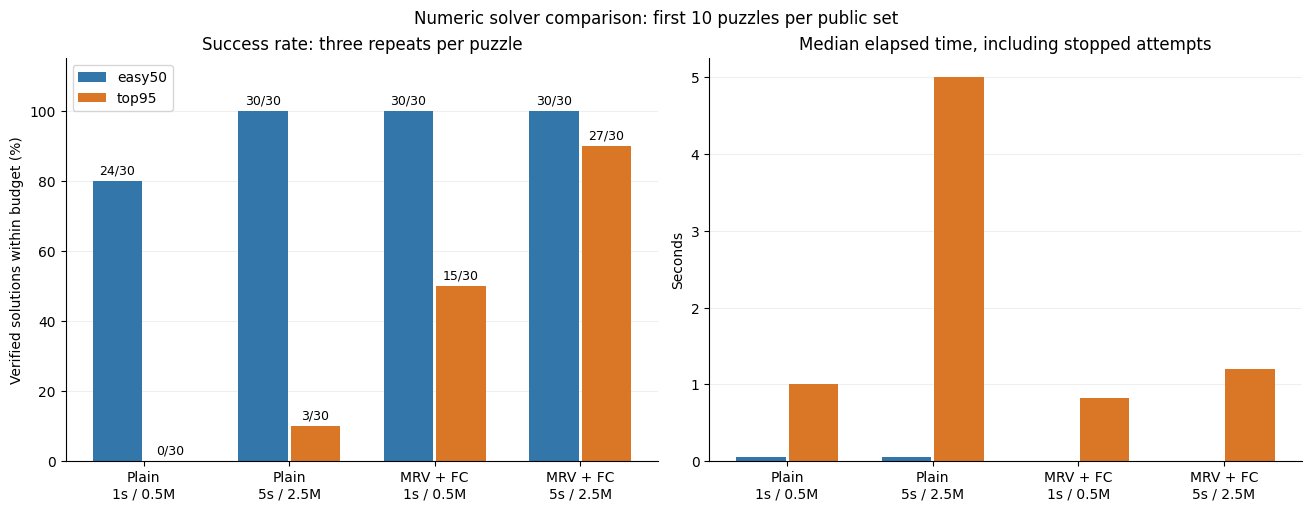

In [38]:
# TW - 02/11/2026 - Run both methods under both budgets; set False to skip this optional experiment.
RUN_SOLVER_COMPARISON = False

"""Measure the effects of search budget and MRV with forward checking separately."""
import csv
import hashlib
import json
from pathlib import Path
import platform
import statistics
import matplotlib.pyplot as plt


# TW - 02/11/2026 - A 2-by-2 comparison holds the puzzles and repetitions fixed while varying method and budget.
EXPERIMENTS = [
    dict(id='plain_original', method='backtracking', budget='original', time_limit=1.0, candidate_limit=500_000),
    dict(id='plain_increased', method='backtracking', budget='increased', time_limit=5.0, candidate_limit=2_500_000),
    dict(id='mrv_fc_original', method='mrv_fc', budget='original', time_limit=1.0, candidate_limit=500_000),
    dict(id='mrv_fc_increased', method='mrv_fc', budget='increased', time_limit=5.0, candidate_limit=2_500_000),
]
COUNTERS = ['candidates', 'assignments', 'checks', 'backtracks',
            'forward_checks', 'pruned_values', 'domain_wipeouts']


# TW - 02/11/2026 - Rotate execution order; keep all 240 attempts, including timeouts and candidate-limit outcomes.
def run_comparison(cases, output_dir='.', repetitions=3):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    solvers = {'backtracking': solve_board, 'mrv_fc': solve_board_mrv_fc}
    rows = []
    for case_index, case in enumerate(cases):
        for repeat in range(1, repetitions + 1):
            offset = (case_index + repeat - 1) % len(EXPERIMENTS)
            order = EXPERIMENTS[offset:] + EXPERIMENTS[:offset]
            for experiment in order:
                original = [row.copy() for row in case['board']]
                result = solvers[experiment['method']](case['board'],
                    time_limit=experiment['time_limit'], node_limit=experiment['candidate_limit'])
                assert case['board'] == original, 'A solver modified the benchmark input'
                valid = None if result['solution'] is None else verify_solution(original, result['solution'])
                assert valid is not False, 'A solver returned an invalid completion'
                assert result['status'] != 'solved' or valid is True
                rows.append(dict(experiment=experiment['id'], method=experiment['method'],
                    budget=experiment['budget'], time_limit=experiment['time_limit'],
                    candidate_limit=experiment['candidate_limit'], id=case['id'], group=case['group'],
                    repeat=repeat, status=result['status'], seconds=result['seconds'],
                    solution_verified=valid,
                    **{name: result['stats'].get(name, 0) for name in COUNTERS}))
        print(f"Completed {case['id']} ({case_index + 1}/{len(cases)} puzzles)", flush=True)

    summary = []
    for experiment in EXPERIMENTS:
        for group in ('easy50', 'top95'):
            trials = [r for r in rows if r['experiment'] == experiment['id'] and r['group'] == group]
            ids = sorted({r['id'] for r in trials})
            solved = [r for r in trials if r['status'] == 'solved']
            summary.append(dict(experiment=experiment['id'], method=experiment['method'],
                budget=experiment['budget'], group=group, puzzles=len(ids), trials=len(trials),
                solved_trials=len(solved),
                puzzles_solved_every_repeat=sum(all(r['status'] == 'solved' for r in trials if r['id'] == i) for i in ids),
                timeout_trials=sum(r['status'] == 'timeout' for r in trials),
                candidate_limit_trials=sum(r['status'] == 'limit_reached' for r in trials),
                other_unsolved_trials=sum(r['status'] not in ('solved', 'timeout', 'limit_reached') for r in trials),
                median_seconds_all_trials=statistics.median(r['seconds'] for r in trials),
                median_seconds_solved=statistics.median(r['seconds'] for r in solved) if solved else None))

    # TW - 02/11/2026 - Save raw measurements, group summaries and the environment separately from previous benchmark runs.
    for name, data in [('solver_comparison_results.csv', rows), ('solver_comparison_summary.csv', summary)]:
        with (output_dir / name).open('w', newline='') as stream:
            writer = csv.DictWriter(stream, fieldnames=list(data[0]))
            writer.writeheader()
            writer.writerows(data)
    manifest = dict(
        environment=dict(python=platform.python_version(), platform=platform.platform()),
        sources=['https://norvig.com/easy50.txt', 'https://norvig.com/top95.txt'],
        selection='First 10 puzzles from each collection, in file order',
        cases_sha256=hashlib.sha256(json.dumps(cases, sort_keys=True).encode()).hexdigest(),
        experiments=EXPERIMENTS, repetitions=repetitions,
        order='Rotated by puzzle index and repeat',
        timing='Solver-reported elapsed time; MRV domain initialization is included. Verification and plotting are excluded.',
        counters='candidates: branching values tried; MRV domains prefilter illegal digits. checks: board-entry comparisons. forward_checks: unassigned-peer domain visits. These operation counts are reported separately.',
        interpretation='Stopped attempts remain in the data. Median time across all attempts is not time to a successful solution. This experiment measures numeric search, not OCR.',
        summary=summary)
    (output_dir / 'solver_comparison_manifest.json').write_text(json.dumps(manifest, indent=2))
    print('\nSUMMARY: each group has 10 puzzles and 30 attempts', flush=True)
    print(f"{'Experiment':<20} {'Set':<7} {'Solved':>8} {'All 3':>7} {'Timeout':>8} {'Cap':>5} {'Median/all':>11}")
    for row in summary:
        print(f"{row['experiment']:<20} {row['group']:<7} {row['solved_trials']:>5}/30 "
              f"{row['puzzles_solved_every_repeat']:>4}/10 {row['timeout_trials']:>8} "
              f"{row['candidate_limit_trials']:>5} {row['median_seconds_all_trials']:>10.4f}s", flush=True)
    print('All returned solutions passed the Sudoku and clue-preservation checks.', flush=True)
    print('Files: solver_comparison_results.csv, solver_comparison_summary.csv, solver_comparison_manifest.json', flush=True)

    # TW - 02/11/2026 - Plot success within budget and elapsed time including stopped attempts; do not label capped times as solution speed.
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    labels = ['Plain\n1s / 0.5M', 'Plain\n5s / 2.5M', 'MRV + FC\n1s / 0.5M', 'MRV + FC\n5s / 2.5M']
    for group_index, (group, color) in enumerate([('easy50', '#3377AA'), ('top95', '#D97727')]):
        values = [next(r for r in summary if r['experiment'] == e['id'] and r['group'] == group) for e in EXPERIMENTS]
        positions = [i + (group_index - 0.5) * 0.36 for i in range(4)]
        bars = axes[0].bar(positions, [100*r['solved_trials']/r['trials'] for r in values],
                           width=0.34, label=group, color=color)
        axes[0].bar_label(bars, labels=[f"{r['solved_trials']}/{r['trials']}" for r in values], fontsize=9, padding=3)
        axes[1].bar(positions, [r['median_seconds_all_trials'] for r in values],
                    width=0.34, label=group, color=color)
    for ax in axes:
        ax.set_xticks(range(4), labels)
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(axis='y', alpha=0.2)
        ax.set_axisbelow(True)
    axes[0].set_ylim(0, 115)
    axes[0].set_ylabel('Verified solutions within budget (%)')
    axes[0].set_title('Success rate: three repeats per puzzle')
    axes[0].legend()
    axes[1].set_ylabel('Seconds')
    axes[1].set_title('Median elapsed time, including stopped attempts')
    fig.suptitle('Numeric solver comparison: first 10 puzzles per public set')
    fig.savefig(output_dir / 'solver_comparison.png', dpi=180)
    plt.show()
    plt.close(fig)
    return rows, summary



# TW - 02/11/2026 - Embed exactly the same public cases so Section 8 can run without rerunning Section 7.
COMPARISON_CASES = [{'id': 'easy50_01', 'group': 'easy50', 'source_index': 1, 'board': [[0, 0, 3, 0, 2, 0, 6, 0, 0], [9, 0, 0, 3, 0, 5, 0, 0, 1], [0, 0, 1, 8, 0, 6, 4, 0, 0], [0, 0, 8, 1, 0, 2, 9, 0, 0], [7, 0, 0, 0, 0, 0, 0, 0, 8], [0, 0, 6, 7, 0, 8, 2, 0, 0], [0, 0, 2, 6, 0, 9, 5, 0, 0], [8, 0, 0, 2, 0, 3, 0, 0, 9], [0, 0, 5, 0, 1, 0, 3, 0, 0]]}, {'id': 'easy50_02', 'group': 'easy50', 'source_index': 2, 'board': [[2, 0, 0, 0, 8, 0, 3, 0, 0], [0, 6, 0, 0, 7, 0, 0, 8, 4], [0, 3, 0, 5, 0, 0, 2, 0, 9], [0, 0, 0, 1, 0, 5, 4, 0, 8], [0, 0, 0, 0, 0, 0, 0, 0, 0], [4, 0, 2, 7, 0, 6, 0, 0, 0], [3, 0, 1, 0, 0, 7, 0, 4, 0], [7, 2, 0, 0, 4, 0, 0, 6, 0], [0, 0, 4, 0, 1, 0, 0, 0, 3]]}, {'id': 'easy50_03', 'group': 'easy50', 'source_index': 3, 'board': [[0, 0, 0, 0, 0, 0, 9, 0, 7], [0, 0, 0, 4, 2, 0, 1, 8, 0], [0, 0, 0, 7, 0, 5, 0, 2, 6], [1, 0, 0, 9, 0, 4, 0, 0, 0], [0, 5, 0, 0, 0, 0, 0, 4, 0], [0, 0, 0, 5, 0, 7, 0, 0, 9], [9, 2, 0, 1, 0, 8, 0, 0, 0], [0, 3, 4, 0, 5, 9, 0, 0, 0], [5, 0, 7, 0, 0, 0, 0, 0, 0]]}, {'id': 'easy50_04', 'group': 'easy50', 'source_index': 4, 'board': [[0, 3, 0, 0, 5, 0, 0, 4, 0], [0, 0, 8, 0, 1, 0, 5, 0, 0], [4, 6, 0, 0, 0, 0, 0, 1, 2], [0, 7, 0, 5, 0, 2, 0, 8, 0], [0, 0, 0, 6, 0, 3, 0, 0, 0], [0, 4, 0, 1, 0, 9, 0, 3, 0], [2, 5, 0, 0, 0, 0, 0, 9, 8], [0, 0, 1, 0, 2, 0, 6, 0, 0], [0, 8, 0, 0, 6, 0, 0, 2, 0]]}, {'id': 'easy50_05', 'group': 'easy50', 'source_index': 5, 'board': [[0, 2, 0, 8, 1, 0, 7, 4, 0], [7, 0, 0, 0, 0, 3, 1, 0, 0], [0, 9, 0, 0, 0, 2, 8, 0, 5], [0, 0, 9, 0, 4, 0, 0, 8, 7], [4, 0, 0, 2, 0, 8, 0, 0, 3], [1, 6, 0, 0, 3, 0, 2, 0, 0], [3, 0, 2, 7, 0, 0, 0, 6, 0], [0, 0, 5, 6, 0, 0, 0, 0, 8], [0, 7, 6, 0, 5, 1, 0, 9, 0]]}, {'id': 'easy50_06', 'group': 'easy50', 'source_index': 6, 'board': [[1, 0, 0, 9, 2, 0, 0, 0, 0], [5, 2, 4, 0, 1, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 7, 0], [0, 5, 0, 0, 0, 8, 1, 0, 2], [0, 0, 0, 0, 0, 0, 0, 0, 0], [4, 0, 2, 7, 0, 0, 0, 9, 0], [0, 6, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 3, 0, 9, 4, 5], [0, 0, 0, 0, 7, 1, 0, 0, 6]]}, {'id': 'easy50_07', 'group': 'easy50', 'source_index': 7, 'board': [[0, 4, 3, 0, 8, 0, 2, 5, 0], [6, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 1, 0, 9, 4], [9, 0, 0, 0, 0, 4, 0, 7, 0], [0, 0, 0, 6, 0, 8, 0, 0, 0], [0, 1, 0, 2, 0, 0, 0, 0, 3], [8, 2, 0, 5, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 5], [0, 3, 4, 0, 9, 0, 7, 1, 0]]}, {'id': 'easy50_08', 'group': 'easy50', 'source_index': 8, 'board': [[4, 8, 0, 0, 0, 6, 9, 0, 2], [0, 0, 2, 0, 0, 8, 0, 0, 1], [9, 0, 0, 3, 7, 0, 0, 6, 0], [8, 4, 0, 0, 1, 0, 2, 0, 0], [0, 0, 3, 7, 0, 4, 1, 0, 0], [0, 0, 1, 0, 6, 0, 0, 4, 9], [0, 2, 0, 0, 8, 5, 0, 0, 7], [7, 0, 0, 9, 0, 0, 6, 0, 0], [6, 0, 9, 2, 0, 0, 0, 1, 8]]}, {'id': 'easy50_09', 'group': 'easy50', 'source_index': 9, 'board': [[0, 0, 0, 9, 0, 0, 0, 0, 2], [0, 5, 0, 1, 2, 3, 4, 0, 0], [0, 3, 0, 0, 0, 0, 1, 6, 0], [9, 0, 8, 0, 0, 0, 0, 0, 0], [0, 7, 0, 0, 0, 0, 0, 9, 0], [0, 0, 0, 0, 0, 0, 2, 0, 5], [0, 9, 1, 0, 0, 0, 0, 5, 0], [0, 0, 7, 4, 3, 9, 0, 2, 0], [4, 0, 0, 0, 0, 7, 0, 0, 0]]}, {'id': 'easy50_10', 'group': 'easy50', 'source_index': 10, 'board': [[0, 0, 1, 9, 0, 0, 0, 0, 3], [9, 0, 0, 7, 0, 0, 1, 6, 0], [0, 3, 0, 0, 0, 5, 0, 0, 7], [0, 5, 0, 0, 0, 0, 0, 0, 9], [0, 0, 4, 3, 0, 2, 6, 0, 0], [2, 0, 0, 0, 0, 0, 0, 7, 0], [6, 0, 0, 1, 0, 0, 0, 3, 0], [0, 4, 2, 0, 0, 7, 0, 0, 6], [5, 0, 0, 0, 0, 6, 8, 0, 0]]}, {'id': 'top95_01', 'group': 'top95', 'source_index': 1, 'board': [[4, 0, 0, 0, 0, 0, 8, 0, 5], [0, 3, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 7, 0, 0, 0, 0, 0], [0, 2, 0, 0, 0, 0, 0, 6, 0], [0, 0, 0, 0, 8, 0, 4, 0, 0], [0, 0, 0, 0, 1, 0, 0, 0, 0], [0, 0, 0, 6, 0, 3, 0, 7, 0], [5, 0, 0, 2, 0, 0, 0, 0, 0], [1, 0, 4, 0, 0, 0, 0, 0, 0]]}, {'id': 'top95_02', 'group': 'top95', 'source_index': 2, 'board': [[5, 2, 0, 0, 0, 6, 0, 0, 0], [0, 0, 0, 0, 0, 0, 7, 0, 1], [3, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 4, 0, 0, 8, 0, 0], [6, 0, 0, 0, 0, 0, 0, 5, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 4, 1, 8, 0, 0, 0, 0, 0], [0, 0, 0, 0, 3, 0, 0, 2, 0], [0, 0, 8, 7, 0, 0, 0, 0, 0]]}, {'id': 'top95_03', 'group': 'top95', 'source_index': 3, 'board': [[6, 0, 0, 0, 0, 0, 8, 0, 3], [0, 4, 0, 7, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 5, 0, 4, 0, 7, 0], [3, 0, 0, 2, 0, 0, 0, 0, 0], [1, 0, 6, 0, 0, 0, 0, 0, 0], [0, 2, 0, 0, 0, 0, 0, 5, 0], [0, 0, 0, 0, 8, 0, 6, 0, 0], [0, 0, 0, 0, 1, 0, 0, 0, 0]]}, {'id': 'top95_04', 'group': 'top95', 'source_index': 4, 'board': [[4, 8, 0, 3, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 7, 1], [0, 2, 0, 0, 0, 0, 0, 0, 0], [7, 0, 5, 0, 0, 0, 0, 6, 0], [0, 0, 0, 2, 0, 0, 8, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 1, 0, 7, 6, 0, 0, 0], [3, 0, 0, 0, 0, 0, 4, 0, 0], [0, 0, 0, 0, 5, 0, 0, 0, 0]]}, {'id': 'top95_05', 'group': 'top95', 'source_index': 5, 'board': [[0, 0, 0, 0, 1, 4, 0, 0, 0], [0, 3, 0, 0, 0, 0, 2, 0, 0], [0, 7, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 9, 0, 0, 0, 3, 0], [6, 0, 1, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 8, 0], [2, 0, 0, 0, 0, 0, 1, 0, 4], [0, 0, 0, 0, 5, 0, 6, 0, 0], [0, 0, 0, 7, 0, 8, 0, 0, 0]]}, {'id': 'top95_06', 'group': 'top95', 'source_index': 6, 'board': [[0, 0, 0, 0, 0, 0, 5, 2, 0], [0, 8, 0, 4, 0, 0, 0, 0, 0], [0, 3, 0, 0, 0, 9, 0, 0, 0], [5, 0, 1, 0, 0, 0, 6, 0, 0], [2, 0, 0, 7, 0, 0, 0, 0, 0], [0, 0, 0, 3, 0, 0, 0, 0, 0], [6, 0, 0, 0, 1, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 7, 0, 4], [0, 0, 0, 0, 0, 0, 0, 3, 0]]}, {'id': 'top95_07', 'group': 'top95', 'source_index': 7, 'board': [[6, 0, 2, 0, 5, 0, 0, 0, 0], [0, 0, 0, 0, 0, 3, 0, 4, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [4, 3, 0, 0, 0, 8, 0, 0, 0], [0, 1, 0, 0, 0, 0, 2, 0, 0], [0, 0, 0, 0, 0, 0, 7, 0, 0], [5, 0, 0, 2, 7, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 8, 1], [0, 0, 0, 6, 0, 0, 0, 0, 0]]}, {'id': 'top95_08', 'group': 'top95', 'source_index': 8, 'board': [[0, 5, 2, 4, 0, 0, 0, 0, 0], [0, 0, 0, 0, 7, 0, 1, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 8, 0, 2, 0, 0, 0], [3, 0, 0, 0, 0, 0, 6, 0, 0], [0, 9, 0, 5, 0, 0, 0, 0, 0], [1, 0, 6, 0, 3, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 8, 9], [7, 0, 0, 0, 0, 0, 0, 0, 0]]}, {'id': 'top95_09', 'group': 'top95', 'source_index': 9, 'board': [[6, 0, 2, 0, 5, 0, 0, 0, 0], [0, 0, 0, 0, 0, 4, 0, 3, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [4, 3, 0, 0, 0, 8, 0, 0, 0], [0, 1, 0, 0, 0, 0, 2, 0, 0], [0, 0, 0, 0, 0, 0, 7, 0, 0], [5, 0, 0, 2, 7, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 8, 1], [0, 0, 0, 6, 0, 0, 0, 0, 0]]}, {'id': 'top95_10', 'group': 'top95', 'source_index': 10, 'board': [[0, 9, 2, 3, 0, 0, 0, 0, 0], [0, 0, 0, 0, 8, 0, 1, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [1, 0, 7, 0, 4, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 6, 5], [8, 0, 0, 0, 0, 0, 0, 0, 0], [0, 6, 0, 5, 0, 2, 0, 0, 0], [4, 0, 0, 0, 0, 0, 7, 0, 0], [0, 0, 0, 9, 0, 0, 0, 0, 0]]}]

if RUN_SOLVER_COMPARISON:
    comparison_rows, comparison_summary = run_comparison(COMPARISON_CASES)
else:
    print('Search comparison skipped. Set RUN_SOLVER_COMPARISON = True to run it.')


In [39]:
# TW - 02/11/2026 - Keep a plain-text summary separate from charts so Colab output-frame failures cannot hide the measurements.
if not globals().get('comparison_summary'):
    print('Run the Section 8 comparison cell first. No completed comparison is available in this runtime.')
else:
    print('LAST COMPLETED NUMERIC COMPARISON')
    print('First 10 puzzles per set; three repeats per puzzle and configuration.')
    print(f"{'Method and budget':<29} {'easy50 solved':>14} {'top95 solved':>14} {'top95 all 3':>14}")
    for experiment in EXPERIMENTS:
        easy = next(r for r in comparison_summary if r['experiment'] == experiment['id'] and r['group'] == 'easy50')
        hard = next(r for r in comparison_summary if r['experiment'] == experiment['id'] and r['group'] == 'top95')
        method = 'Plain' if experiment['method'] == 'backtracking' else 'MRV + FC'
        label = f"{method} {experiment['time_limit']:g}s / {experiment['candidate_limit']/1_000_000:g}M"
        print(f"{label:<29} {easy['solved_trials']:>10}/30 {hard['solved_trials']:>10}/30 {hard['puzzles_solved_every_repeat']:>10}/10")
    print('Solved = verified completion within budget. All 3 = puzzles completed in every repeat.')
    print('Timeouts and candidate-limit stops remain in the raw CSV. These results do not measure OCR accuracy.')


LAST COMPLETED NUMERIC COMPARISON
First 10 puzzles per set; three repeats per puzzle and configuration.
Method and budget              easy50 solved   top95 solved    top95 all 3
Plain 1s / 0.5M                       24/30          0/30          0/10
Plain 5s / 2.5M                       30/30          3/30          1/10
MRV + FC 1s / 0.5M                    30/30         15/30          5/10
MRV + FC 5s / 2.5M                    30/30         27/30          9/10
Solved = verified completion within budget. All 3 = puzzles completed in every repeat.
Timeouts and candidate-limit stops remain in the raw CSV. These results do not measure OCR accuracy.


In [40]:
# Corney - 03/11/2026 - Marginal-case tests — uses functions already defined in the notebook.
import copy

demo = [
    [5,3,0,0,7,0,0,0,0],
    [6,0,0,1,9,5,0,0,0],
    [0,9,8,0,0,0,0,6,0],
    [8,0,0,0,6,0,0,0,3],
    [4,0,0,8,0,3,0,0,1],
    [7,0,0,0,2,0,0,0,6],
    [0,6,0,0,0,0,2,8,0],
    [0,0,0,4,1,9,0,0,5],
    [0,0,0,0,8,0,0,7,9]
]

# Conflicting clues: duplicate 5 in the first row.
invalid = copy.deepcopy(demo)
invalid[0][2] = 5

# No initial duplicates, but r1c9 needs 9 and column 9 already has 9.
unsatisfiable = [[0] * 9 for _ in range(9)]
unsatisfiable[0] = [1,2,3,4,5,6,7,8,0]
unsatisfiable[1][8] = 9

# Construct a completed valid grid.
completed = [
    [(r * 3 + r // 3 + c) % 9 + 1 for c in range(9)]
    for r in range(9)
]

# Removing all 1s and 2s permits at least two completions:
# the original grid and one with 1 and 2 swapped.
multiple = [
    [0 if value in (1, 2) else value for value in row]
    for row in completed
]

uncertain = copy.deepcopy(demo)
uncertain[0][2] = None

tests = [
    ("Conflicting clues", "invalid",
     lambda: solve_board_mrv_fc(invalid)),

    ("Unsatisfiable puzzle", "no_solution",
     lambda: solve_board_mrv_fc(unsatisfiable)),

    ("Already solved puzzle", "solved",
     lambda: solve_board_mrv_fc(completed)),

    ("Multiple solutions", "multiple",
     lambda: solve_board_mrv_fc(
         multiple, check_unique=True, time_limit=5.0)),

    ("Uncertain OCR", "uncertain_ocr",
     lambda: solve_recognized_board(uncertain, reviewed=True)),

    ("Empty recognition", "empty_recognition",
     lambda: solve_recognized_board(
         [[0] * 9 for _ in range(9)], reviewed=True)),

    ("Review not approved", "review_required",
     lambda: solve_recognized_board(demo, reviewed=False)),

    ("Zero time budget", "timeout",
     lambda: solve_board_mrv_fc(demo, time_limit=0)),

    ("Zero candidate budget", "limit_reached",
     lambda: solve_board_mrv_fc(demo, node_limit=0)),
]

print(f"{'Test':<25} {'Expected':<20} {'Actual':<20} Result")
print("-" * 78)

marginal_results = []

for name, expected, run_test in tests:
    result = run_test()
    actual = result["status"]
    passed = actual == expected

    # Independently verify any returned completion.
    if result.get("solution") is not None:
        source = multiple if name == "Multiple solutions" else completed
        passed = passed and verify_solution(source, result["solution"])

    marginal_results.append({
        "test": name,
        "expected": expected,
        "actual": actual,
        "passed": passed
    })

    print(
        f"{name:<25} {expected:<20} {actual:<20} "
        f"{'PASS' if passed else 'CHECK'}"
    )

Test                      Expected             Actual               Result
------------------------------------------------------------------------------
Conflicting clues         invalid              invalid              PASS
Unsatisfiable puzzle      no_solution          no_solution          PASS
Already solved puzzle     solved               solved               PASS
Multiple solutions        multiple             multiple             PASS
Uncertain OCR             uncertain_ocr        uncertain_ocr        PASS
Empty recognition         empty_recognition    empty_recognition    PASS
Review not approved       review_required      review_required      PASS
Zero time budget          timeout              timeout              PASS
Zero candidate budget     limit_reached        limit_reached        PASS


## 9. Three-method benchmark: plain backtracking, MRV + forward checking, and MAC
Run after the solver definitions and Section 8 case definitions. The MAC solver applies AC-3 initially and after each search assignment. It finds one completion; the original image workflow is unchanged.
Sources: Mackworth (1977), https://doi.org/10.1016/0004-3702(77)90007-8; Sabin and Freuder (1994), *Contradicting conventional wisdom in constraint satisfaction*.


In [ ]:
# Run after the notebook's solver definitions and Section 8 case definitions.
import time
import csv
import statistics
import platform

def solve_board_mac(original, time_limit=5.0, node_limit=2_500_000):
    """MRV backtracking with AC-3 over binary Sudoku peer inequalities."""
    from collections import deque
    start = time.perf_counter()
    if not validate_board(original):
        return dict(status='invalid', solution=None, seconds=0.0)
    positions = list(_PEERS)
    domains = {p: {int(original[p[0]][p[1]])} if original[p[0]][p[1]]
               else set(range(1, 10)) for p in positions}
    attempts = 0
    solution = None

    def check_time():
        if time.perf_counter() - start >= time_limit:
            raise TimeoutError('timeout')

    def ac3(d, arcs):
        queue = deque(arcs)
        while queue:
            check_time()
            x, y = queue.popleft()
            # For x != y, x loses a value only if y has that sole value.
            if len(d[y]) == 1:
                v = next(iter(d[y]))
                if v in d[x]:
                    d[x].remove(v)
                    if not d[x]:
                        return False
                    queue.extend((z, x) for z in _PEERS[x] if z != y)
        return True

    def search(d):
        nonlocal attempts, solution
        check_time()
        x = min((p for p in positions if len(d[p]) > 1),
                key=lambda p: (len(d[p]), p), default=None)
        if x is None:
            solution = [[next(iter(d[r, c])) for c in range(9)] for r in range(9)]
            return True
        for v in sorted(d[x]):
            check_time()
            if attempts >= node_limit:
                raise TimeoutError('limit_reached')
            attempts += 1
            child = {p: values.copy() for p, values in d.items()}
            child[x] = {v}
            if ac3(child, ((y, x) for y in _PEERS[x])) and search(child):
                return True
        return False

    try:
        consistent = ac3(domains, ((x, y) for x in positions for y in _PEERS[x]))
        status = 'solved' if consistent and search(domains) else 'no_solution'
    except TimeoutError as error:
        status = str(error)
    return dict(status=status, solution=solution, seconds=time.perf_counter()-start,
                candidates=attempts)

def benchmark_three_methods(cases, filename='mac_benchmark_trials.csv'):
    methods = [('Plain', solve_board), ('MRV + FC', solve_board_mrv_fc),
               ('MAC', solve_board_mac)]
    rows = []
    print('Python', platform.python_version(), '|', platform.platform(), flush=True)
    for i, case in enumerate(cases):
        for repeat in range(3):
            for seconds, cap in [(1.0, 500_000), (5.0, 2_500_000)]:
                shift = (i + repeat) % len(methods)
                for name, solver in methods[shift:] + methods[:shift]:
                    board = [row[:] for row in case['board']]
                    result = solver(board, time_limit=seconds, node_limit=cap)
                    assert board == case['board']
                    if result['status'] == 'solved':
                        assert verify_solution(case['board'], result['solution'])
                    rows.append(dict(case=case['id'], group=case['group'],
                                     repeat=repeat+1, method=name, budget=seconds,
                                     candidate_cap=cap, status=result['status'],
                                     seconds=result['seconds']))
        print('Finished', case['id'], flush=True)
    with open(filename, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=rows[0])
        writer.writeheader()
        writer.writerows(rows)
    print('Method | Set | Budget | Verified | Timeout | Cap | Median s (all)')
    for name, _ in methods:
        for group in ('easy50', 'top95'):
            for budget in (1.0, 5.0):
                runs = [r for r in rows if (r['method'],r['group'],r['budget']) == (name,group,budget)]
                count = lambda status: sum(r['status']==status for r in runs)
                print(f"{name} | {group} | {budget:g}s | {count('solved')}/{len(runs)} | "
                      f"{count('timeout')} | {count('limit_reached')} | "
                      f"{statistics.median(r['seconds'] for r in runs):.4f}", flush=True)
    return rows

# In Colab, set RUN_SOLVER_COMPARISON = False in Section 8 to skip the old
# two-method run. Run that section so COMPARISON_CASES is still defined.
three_method_rows = benchmark_three_methods(COMPARISON_CASES)
